# 14 Paper figures

```
Author: Danielle Lindsay
Environment: environment.yml. Runs last. About 2 min.
```

**What this notebook does**

1. **Fig 1** (section 2), from the products of notebook 04 (`fig1_inputs.npz`).
2. **Fig 2** and its line-of-sight version for the supplement (sections 3 to 14), from the maps and profiles of
   notebook 06, the samples of notebook 07, the homogeneous model of notebook 08 and the preferred slip model of
   notebook 09.
3. **Fig 3** (section 15), from the products of notebooks 11, 12 and 13.
4. **Collect** every paper and supplement figure under its manuscript name (last section), after checking that none
   is missing, that each file pattern matches one file, and that no figure is older than the notebooks it depends on.

The supplement figures are drawn by the notebook that computes their content. No number is registered here; each
number on a figure is registered by the notebook that computes it.

**Inputs**: `04_event_detection/fig1_inputs.npz`; `06_event_field_geometry/fig2_inputs.npz`;
`07_model_data/model_data.npz`; `08_model_homogeneous/homogeneous_model.npz`; `09_model_3d/selected_model.npz`;
`04_event_detection/event_fraction_by_crossing.csv`; the Fig 3 products of notebooks 11, 12 and 13; the trace,
the alignment-array summary, the Fremont rain gauge, the GNSS station list of the descending frame and the CFW1
position; the executed notebooks (their cell execution records give the time of each notebook's latest run).

**Outputs**: `Figures_<date>/paper/Fig_<name>.png` and `.pdf`; small GMT helper files in
`outputs/14_paper_figures/cpt/`.

**Figures**: `fig1_tulepond_<params>_band90` (Fig 1), `fig2_fp_up_coh<c>_<n>ev_model3d_<dip>` (Fig 2; fp = fault-parallel,
up = vertical component, <dip> = `model_config.selected_dip_tag`), `figS_los_maps_profiles_coh<c>_<n>ev_model3d_<dip>`
(supplement), `fig3_history_forecast_*` (Fig 3).

**What to check**
- Section 9: both model products are on the samples of notebook 07, and I = model + plane and J = E - I (asserted).
- Section 14: the per-block amplitudes printed for Fig 2 equal the registry rows `06_XX_*` and `06_YY_*`.
- Last section: each row prints its source file and notebook; the cell stops if a figure is missing or stale.

## 1. Imports

In [1]:
import glob
import json
import os
import shutil

import numpy as np
import pandas as pd
import pyproj
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator
from scipy.interpolate import griddata
from scipy.spatial import cKDTree
import pygmt

import insar_utils as utils
import model_utils
import model_config as cfg                         # the dip of the preferred model, in the figure names
from TulePond_filepaths import (alameda_creek_trace_lonlat, lake_elizabeth_trace_lonlat, common_paths, creepmeters, params,
                                paths_out, paths_gps, des11115_dic, fig2_map_centre_km, fig2_map_half_km, fig2_map_extra_km,
                                forecast_issue_date, repo_dir)

this_run_start = pd.Timestamp.now(tz="UTC")       # the figures drawn here must be written after this

## 2. Fig 1

Fig 1 is drawn in pygmt, with one font, from `fig1_inputs.npz` (notebook 04, section 14). (A) The
fault-parallel velocity (notebook 02) on a page rotated to the mean strike, with the creepmeters (gold
triangles, as in D), city labels and a distance axis down the left edge. The bracket is the length of fault
hosting the events (notebook 04, section 10). (B) Tule Pond: the slip above each crossing's own inter-event
rate in the window (notebook 04, section 9), with the earthquakes (circles coloured by depth and sized by
magnitude) and the repeating earthquakes (white squares) of notebook 04, section 13. The dashed lines mark
the 90 % band. (C) The cumulative slip of each event along strike (blues, light to dark in time). (D) The
creep rates: inter-event (bluish green), event-driven (orange, the five Tule Pond events) and their sum
(black), smoothed along the fault with the 0.5 km Gaussian of the supplement creep-rate figure, with the
creepmeters over the InSAR window (gold) and the whole-record alignment-array rates of the USGS archive (reddish
purple open diamonds, as in the supplement creep-rate figure). The error bars are 1 sigma (1 standard error for
the arrays). (E) The InSAR stack: the mean fault-parallel series of the
band crossings, zeroed at the first epoch with nothing subtracted, and the joint model drawn over it (bluish
green between events, orange across the steps). The colours are from the Okabe-Ito palette.

The strike frame of the map is rebuilt from the EPSG code, the strike and the trace stored in the file.

In [2]:
f_fig1_in = os.path.join(paths_out["04_event_detection"], "fig1_inputs.npz")
fig_dir = common_paths["fig_dir"]
fig1_in = np.load(f_fig1_in)
print(str(fig1_in["provenance"]))

# A) the map grid, the strike frame and the extent of the events
trace_lon = fig1_in["trace_lon"]
trace_lat = fig1_in["trace_lat"]
frame = utils.strike_frame(int(fig1_in["epsg"]), float(fig1_in["strike_map"]), trace_lon, trace_lat)
grid_ll = xr.DataArray(fig1_in["fp_lonlat"], coords={"lat": fig1_in["lat_axis"], "lon": fig1_in["lon_axis"]}, dims=("lat", "lon"))
len_lo = float(fig1_in["len_lo"])
len_hi = float(fig1_in["len_hi"])

# B) the Hovmöller diagram, the window, the band and the catalogues in the window
grid_hov = xr.DataArray(fig1_in["hovmoller"], coords={"y": fig1_in["hov_km"], "x": fig1_in["t_regular"]}, dims=("y", "x"))
vmin = float(fig1_in["vmin"])
vmax = float(fig1_in["vmax"])
t0 = float(fig1_in["t0"])
t1 = float(fig1_in["t1"])
w_lo = float(fig1_in["w_lo"])
w_hi = float(fig1_in["w_hi"])
band_lo = float(fig1_in["band_lo"])
band_hi = float(fig1_in["band_hi"])
band_main = float(fig1_in["band_main"])
seis_window = pd.DataFrame({"YYYY": fig1_in["seis_yr"], "km": fig1_in["seis_km"], "Mag": fig1_in["seis_mag"], "Depth": fig1_in["seis_depth"]})
cre_window = pd.DataFrame({"YYYY": fig1_in["cre_yr"], "km": fig1_in["cre_km"]})

# C) the per-event cumulative profiles
cum_prof = fig1_in["cum_prof"]
km_window = fig1_in["km_window"]
step_epochs_tulepond = fig1_in["step_epochs"]

# D) the creep rates, the alignment arrays and the creepmeters
km_budget = fig1_in["km_budget"]
rate_lines = {}
rate_bands = {}
for name in ("secular", "event_rate", "total"):
    rate_lines[name] = fig1_in[f"rate_line_{name}"]
    rate_bands[name] = fig1_in[f"rate_band_{name}"]
rate_band_half_km = float(fig1_in["rate_band_half_km"])
span = float(fig1_in["span"])
aa_rates = pd.DataFrame({"km": fig1_in["aa_km"], "rate": fig1_in["aa_rate_longterm"], "rate_se": fig1_in["aa_rate_longterm_se"]})   # whole record
cm_rates = {}                                    # code -> (km, mm/yr), in the order of TulePond_filepaths
cm_rate_sigma = {}                               # code -> 1 sigma (mm/yr)
for code, km_cm, rate_cm, sigma_cm in zip(fig1_in["cm_codes"], fig1_in["cm_km"], fig1_in["cm_rate"], fig1_in["cm_rate_sigma"]):
    cm_rates[str(code)] = (float(km_cm), float(rate_cm))
    cm_rate_sigma[str(code)] = float(sigma_cm)

# E) the band stack and its model
dates = fig1_in["dates"]
band_main_stack = dict(mean=fig1_in["stack_mean"], std=fig1_in["stack_std"], n=int(fig1_in["stack_n"]),
                       secular=float(fig1_in["stack_secular"]), steps=fig1_in["stack_steps"])
model_full = fig1_in["model_full"]
is_event_epoch = fig1_in["is_event_epoch"]
event_epochs_wide = fig1_in["event_epochs_wide"]
assert band_main_stack["mean"].size == dates.size == model_full.size, "the stack and the dates differ in length"

04_event_detection | git 1037fcc+ | 2026-11-01 12:36


map panel 2.85 x 9.20 cm at true scale


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


Saved Fig 1 to: /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-01/fig1_tulepond_ap30-150m_coh0.7_mp5_sw200m_band90.png


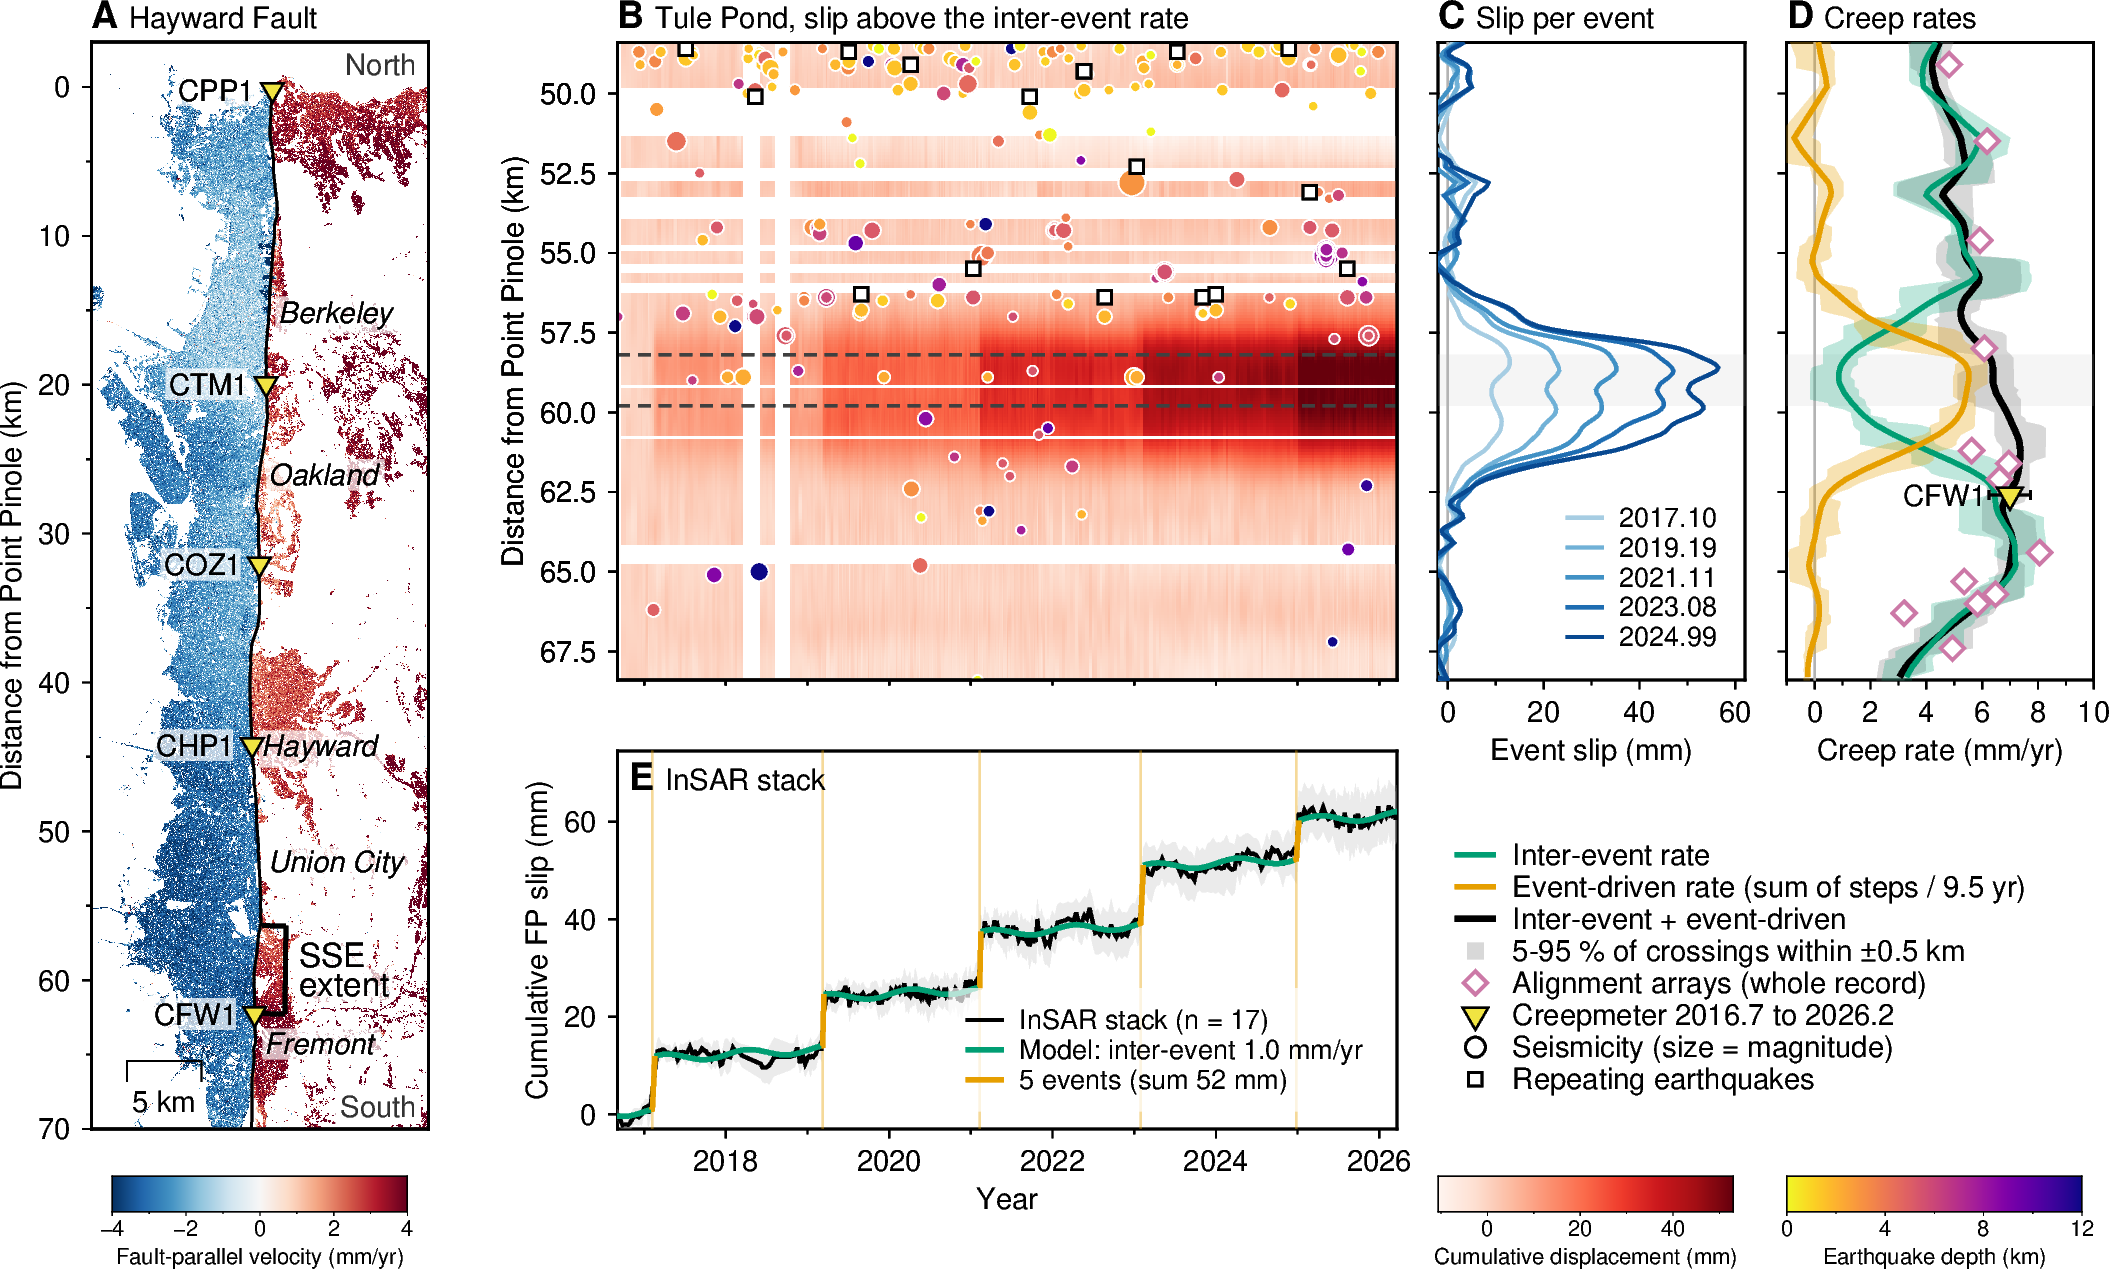

In [3]:
# --- sizes in cm, double-column width, one font ---
green = "#009E73"                                # Okabe-Ito bluish green: inter-event rate
orange = "#E69F00"                               # Okabe-Ito orange: event-driven
gold = "#F0E442"                                 # Okabe-Ito yellow: creepmeters
hov_w, hov_h = 6.6, 5.4                          # hovmoller (6.6 cm keeps the page at the 18.3 cm Science full width)
stack_h = 3.2                                    # stack: shorter than the hovmoller, so B carries the figure
gap_stack = 0.6                                  # between B and E (B has no x annotation, E has its label inside)
map_h = hov_h + gap_stack + stack_h               # map: as tall as B + gap + E, so the tops and bottoms line up (its width follows, true scale)
profile_w, rates_w, profile_h = 2.6, 2.6, hov_h  # profiles and rates panels: the same width
gap_map, gap_p, gap_r = 1.6, 0.35, 0.35          # B, C and D share one y axis, so the gaps are just the tick length
cb_w = 2.5                                       # every colour bar the same size and font (14p trick -> 7 pt)
vel_lim = 4.0                                    # map colour range +/- this (mm/yr)
cpt_dir = os.path.join(paths_out["14_paper_figures"], "cpt")
os.makedirs(cpt_dir, exist_ok=True)
cpt_vel = utils.write_cpt(os.path.join(cpt_dir, "vel_vik.cpt"), "RdBu_r", -vel_lim, vel_lim)
cpt_hov = utils.write_cpt(os.path.join(cpt_dir, "hov_reds.cpt"), "Reds", vmin, vmax)
cpt_dep = utils.write_cpt(os.path.join(cpt_dir, "depth_plasma_r.cpt"), "plasma_r", 0, 12)

fig = pygmt.Figure()
pygmt.config(FONT="8p,Helvetica", FONT_ANNOT_PRIMARY="7p,Helvetica", FONT_LABEL="7p,Helvetica", FONT_TITLE="9p,Helvetica-Bold",
             MAP_FRAME_TYPE="plain", MAP_FRAME_PEN="0.6p", MAP_TICK_LENGTH_PRIMARY="2p", MAP_LABEL_OFFSET="4p", MAP_ANNOT_OFFSET="3p")

# A) the map: the shared rotated fault map (utils.fault_map_panel, also the 05 and 11 supplements): oblique
# Mercator, fault up the page, north at the top, true scale, map_h tall. The bracket ("SSE extent") spans the
# Tule Pond creep length (len_lo-len_hi, the length of fault hosting the events; section_lengths.csv), not the
# narrower stacked band, which is drawn as the dashed lines in B. The cities, the creepmeter triangles (drawn
# above every label) and the distance axis are drawn by the same function.
map_w = utils.fault_map_panel(fig, frame, grid_ll, cpt_vel, map_h, trace_lon, trace_lat,
                              creepmeters, (len_lo, len_hi), letter="A", title="Hayward Fault",
                              colorbar_frame="xa2f1+lFault-parallel velocity (mm/yr)")

# B) hovmoller, top of the middle column
fig.shift_origin(xshift=f"{map_w + gap_map}c", yshift=f"{map_h - hov_h}c")
region_hov = [t0, t1, w_lo, w_hi]
fig.basemap(region=region_hov, projection=f"X{hov_w}c/-{hov_h}c", frame=["WStr", "xf1", "ya2.5+lDistance from Point Pinole (km)"])
fig.grdimage(grid=grid_hov, cmap=cpt_hov, nan_transparent=True)
fig.plot(x=seis_window.YYYY.values, y=seis_window.km.values, style="c", size=0.09 + 0.05 * np.clip(seis_window.Mag.values, 0, 5),
         fill=seis_window.Depth.values, cmap=cpt_dep, pen="0.3p,white")
fig.plot(x=cre_window.YYYY.values, y=cre_window.km.values, style="s0.16c", fill="white", pen="0.6p,black")
for band_edge_km in (band_lo, band_hi):
    fig.plot(x=[t0, t1], y=[band_edge_km, band_edge_km], pen="0.7p,gray25,3_2")
fig.text(x=t0, y=w_lo, text="@%Helvetica-Bold%B@%% @:7p:Tule Pond, slip above the inter-event rate@::", justify="BL", offset="0c/0.12c", font="9p,Helvetica", no_clip=True)
fig.basemap(region=region_hov, projection=f"X{hov_w}c/-{hov_h}c", frame=["WStr", "xf1", "ya2.5+lDistance from Point Pinole (km)"])   # frame on top: a clean edge

# E) the stack, bottom of the middle column, bottom aligned with the map
fig.shift_origin(yshift=f"-{stack_h + gap_stack}c")
ok_stack = np.isfinite(band_main_stack["mean"])
region_stack = [t0, t1, -3, float(np.nanmax(band_main_stack["mean"] + band_main_stack["std"])) * 1.08]
fig.basemap(region=region_stack, projection=f"X{hov_w}c/{stack_h}c", frame=["WStr", "xa2f1+lYear", "ya20+lCumulative FP slip (mm)"])
envelope_x = np.r_[dates[ok_stack], dates[ok_stack][::-1]]
envelope_y = np.r_[(band_main_stack["mean"] + band_main_stack["std"])[ok_stack], (band_main_stack["mean"] - band_main_stack["std"])[ok_stack][::-1]]
fig.plot(x=envelope_x, y=envelope_y, fill="gray@70", close=True)
for step_epoch in step_epochs_tulepond:
    fig.plot(x=[step_epoch, step_epoch], y=[region_stack[2], region_stack[3]], pen="0.5p," + orange + "@60")
fig.plot(x=dates[ok_stack], y=band_main_stack["mean"][ok_stack], pen="0.9p,black", label=f"InSAR stack (n = {band_main_stack['n']})")
fig.plot(x=dates, y=np.where(is_event_epoch, np.nan, model_full), pen="1.2p," + green, label=f"Model: inter-event {band_main_stack['secular']:.1f} mm/yr")
fig.plot(x=dates, y=np.where(event_epochs_wide, model_full, np.nan), pen="1.2p," + orange,
         label=f"{step_epochs_tulepond.size} events (sum {np.sum(band_main_stack['steps']):.0f} mm)")
fig.text(position="TL", text="@%Helvetica-Bold%E@%% @:7p:InSAR stack@::", font="9p,Helvetica", offset="0.1c/-0.1c")
with pygmt.config(FONT_ANNOT_PRIMARY="6.5p"):
    fig.legend(position="JBR+jBR+o0.15c/0.15c", box="+gwhite@30")

# C) cumulative slip per event, right of the hovmoller
fig.shift_origin(xshift=f"{hov_w + gap_p}c", yshift=f"{stack_h + gap_stack}c")
xmax_profile = float(np.nanmax(cum_prof)) * 1.1
fig.basemap(region=[-2, xmax_profile, w_lo, w_hi], projection=f"X{profile_w}c/-{profile_h}c", frame=["wStr", "xa20f10+lEvent slip (mm)", "ya2.5"])
fig.plot(x=[-2, xmax_profile, xmax_profile, -2], y=[band_lo, band_lo, band_hi, band_hi], fill="gray@85", close=True)
fig.plot(x=[0, 0], y=[w_lo, w_hi], pen="0.4p,gray70")
blues = plt.get_cmap("Blues")                       # C: the five events, light (first) to dark (last)
n_profiles = step_epochs_tulepond.size
for i, step_epoch in enumerate(step_epochs_tulepond):
    colour = "/".join(str(int(255 * v)) for v in blues(0.35 + 0.55 * i / (n_profiles - 1))[:3])    # GMT r/g/b
    fig.plot(x=cum_prof[i], y=km_window, pen=f"0.9p,{colour}", label=f"{step_epoch:.2f}")      # each event labelled by its step epoch
fig.text(x=-2, y=w_lo, text="@%Helvetica-Bold%C@%% @:7p:Slip per event@::", justify="BL", offset="0c/0.12c", font="9p,Helvetica", no_clip=True)
with pygmt.config(FONT_ANNOT_PRIMARY="6.5p"):
    fig.legend(position="JBR+jBR+o0.1c/0.1c", box=False)

# D) creep rates: its y axis is shared with B, so no annotation
fig.shift_origin(xshift=f"{profile_w + gap_r}c")
fig.basemap(region=[-1, 10, w_lo, w_hi], projection=f"X{rates_w}c/-{profile_h}c", frame=["wStr", "xa2f1+lCreep rate (mm/yr)", "ya2.5"])
fig.plot(x=[-1, 10, 10, -1], y=[band_lo, band_lo, band_hi, band_hi], fill="gray@85", close=True)
fig.plot(x=[0, 0], y=[w_lo, w_hi], pen="0.4p,gray70")
# the 5-95 % shading, then the lines, each stacked black (bottom), green, orange (top)
rate_style = {"total": ("gray50@70", "1.5p,black"), "secular": (green + "@75", "1.2p," + green), "event_rate": (orange + "@70", "1.2p," + orange)}
for name in ("total", "secular", "event_rate"):
    band_lo_hi = rate_bands[name]
    has_band = np.isfinite(band_lo_hi[:, 0])
    run_id = np.cumsum(np.r_[True, np.diff(has_band.astype(int)) != 0])        # one polygon per run of crossings with a band
    for run in np.unique(run_id[has_band]):
        in_run = has_band & (run_id == run)
        if in_run.sum() < 2:
            continue
        fig.plot(x=np.r_[band_lo_hi[in_run, 0], band_lo_hi[in_run, 1][::-1]], y=np.r_[km_budget[in_run], km_budget[in_run][::-1]],
                 fill=rate_style[name][0], close=True)
rate_labels = {"total": "Inter-event + event-driven", "secular": "Inter-event rate", "event_rate": f"Event-driven rate (sum of steps / {span:.1f} yr)"}
for name in ("total", "secular", "event_rate"):
    fig.plot(x=rate_lines[name], y=km_budget, pen=rate_style[name][1])
# legend entries in the reading order (inter-event, event-driven, sum, shading): plotted off-region, so only the legend records them
for name in ("secular", "event_rate", "total"):
    fig.plot(x=[-50, -49], y=[w_lo, w_lo], pen=rate_style[name][1], label=rate_labels[name])
fig.plot(x=[-50], y=[w_lo], style="s0.2c", fill="gray50@70", label=f"5-95 % of crossings within ±{rate_band_half_km:g} km")
arrays_window = aa_rates[(aa_rates.km >= w_lo) & (aa_rates.km <= w_hi) & aa_rates.rate.notna()]
aa_purple = "#CC79A7"                                                 # Okabe-Ito reddish purple, as the arrays of the creep-rate figure
fig.plot(data=np.column_stack([arrays_window.rate.values, arrays_window.km.values, arrays_window.rate_se.values]),
         error_bar="x+p0.6p," + aa_purple + "+w0c", style="d0.2c", fill="white", pen="0.8p," + aa_purple,
         label="Alignment arrays (whole record)")                     # +/- 1 standard error
creepmeter_legend_done = False                                        # one legend entry for the creepmeters
for code, (km_cm, rate_cm) in cm_rates.items():
    if w_lo <= km_cm <= w_hi:
        if creepmeter_legend_done:
            legend_label = None
        else:
            legend_label = f"Creepmeter {t0:.1f} to {t1:.1f}"
            creepmeter_legend_done = True
        fig.plot(data=[[rate_cm, km_cm, cm_rate_sigma[code]]], error_bar="x+p0.6p,black+w0.08c", style="i0.25c", fill=gold, pen="0.5p,black",
                 label=legend_label)                                                                             # +/- 1 sigma
        fig.text(x=rate_cm, y=km_cm, text=code, justify="RM", offset="-0.2c/0c", font="7p", no_clip=True)
fig.text(x=-1, y=w_lo, text="@%Helvetica-Bold%D@%% @:7p:Creep rates@::", justify="BL", offset="0c/0.12c", font="9p,Helvetica", no_clip=True)
# legend entries for the symbols drawn in B: plotted off-region (clipped), so only the legend records them
fig.plot(x=[-50], y=[w_lo], style="c0.17c", pen="0.6p,black", label="Seismicity (size = magnitude)")
fig.plot(x=[-50], y=[w_lo], style="s0.16c", fill="white", pen="0.6p,black", label="Repeating earthquakes")
# the legend of D in the free space under C and D
left_of_C = profile_w + gap_r                                          # from D's origin back to C's left edge
with pygmt.config(FONT_ANNOT_PRIMARY="7p"):                          # clear of the axis labels above it
    fig.legend(position=f"JBL+jTL+o-{left_of_C}c/1.2c+w{left_of_C + rates_w}c", box=False)
# the two colour bars of B, side by side, on the same line as the map's bar (0.4 cm below the map bottom)
cb_y = gap_stack + stack_h + 0.4
with pygmt.config(FONT_ANNOT_PRIMARY="13p", FONT_LABEL="13p"):          # -> ~6.5 pt at this bar thickness, as A's
    fig.colorbar(cmap=cpt_hov, position=f"x-{left_of_C}c/-{cb_y:.2f}c+w{cb_w}c/0.3c+h+jTL", frame="xa20f10+lCumulative displacement (mm)")
    fig.colorbar(cmap=cpt_dep, position=f"x0c/-{cb_y:.2f}c+w{cb_w}c/0.3c+h+jTL", frame="xa4f2+lEarthquake depth (km)")

f_fig1 = os.path.join(fig_dir, f"fig1_tulepond_{params}_band{int(band_main * 100)}")
fig.savefig(f_fig1 + ".png", dpi=600, transparent=False, crop="+gwhite", anti_alias=True, show=False)   # +gwhite: opaque page
fig.savefig(f_fig1 + ".pdf", transparent=False, crop="+gwhite", anti_alias=True, show=False)
print("Saved Fig 1 to:", f_fig1 + ".png")
fig.show()

## 3. Constants

Colours (Okabe-Ito), fonts, the running-median bin of the profiles, the map window, the named alignment arrays and the
input files.

In [4]:
notebook = "14_paper_figures"
out_dir = paths_out[notebook]
fig_dir = common_paths["fig_dir"]
cpt_dir = os.path.join(out_dir, "cpt")                 # GMT helper files: CPTs, legend specs, block polygons
os.makedirs(cpt_dir, exist_ok=True)

# the running median drawn on the profiles
median_bin_m = 150.0            # running-median bin (five pixels), taken on each side of the fault separately
median_col = "black"            # per-side running median
grey = "gray55"                 # pixels
homog_col = "#0072B2"           # 08's homogeneous model (Okabe-Ito blue)
hetero_col = "#D55E00"          # the 3D (SFSVM) model, the preferred model (Okabe-Ito vermillion)
model_col = hetero_col

# fonts: the model row (I-L) uses the same sizes as the map and profile panels
panel_letter_font = "9p,Helvetica-Bold"     # A-L (Science: bold capital panel letters)
heading_font = "9p,Helvetica-Bold"          # column headings, row labels, the I/J titles
ylabel_font = "9p,Helvetica"                # the y-axis labels of the profile and model panels
annot_font = "7p,Helvetica"                 # tick annotations, x-axis labels, map labels, the Mw text
legend_font = "6p,Helvetica"                # the line legends (G and K)
profile_label_font = "7p,Helvetica-Bold"    # X, X', Y, Y' on every map and profile panel (one size throughout)
map_bar_font_pt = 13.0                      # the map colour bars ask GMT for 13 pt (GMT shrinks it on the page, see section 7)

# Fig 2 map window (unrotated, north up): centred on the trace at fig2_map_centre_km from Point Pinole,
# +/- fig2_map_half_km east-west, +/- (fig2_map_half_km + fig2_map_extra_km) north-south (10.4 x 12 km).
# The values live in TulePond_filepaths.
aa_labelled = ["HGIL", "HRKT"]  # the arrays used in the paper (notebook 11_alignment_arrays); the other arrays of the section are not drawn
aa_label_pos = {"HGIL": ("RM", "-0.15c/0c"),     # HGIL left of its symbol
                "HRKT": ("LM", "0.15c/0.12c")}   # (justify, offset) of each label about its symbol

f_fig2_in = os.path.join(paths_out["06_event_field_geometry"], "fig2_inputs.npz")
aa_file = common_paths["aa_summary"]
selected_file = os.path.join(paths_out["09_model_3d"], "selected_model.npz")          # the preferred model (notebook 09, section 13)
homogeneous_file = os.path.join(paths_out["08_model_homogeneous"], "homogeneous_model.npz")  # the homogeneous model of 08
model_data_file = os.path.join(paths_out["07_model_data"], "model_data.npz")         # 07's samples
model_tag = f"_model3d_{cfg.selected_dip_tag}"                                         # in the Fig 2 file names: the preferred 3D model
profile_half_width_m = 300.0    # G: model samples within this distance of each profile line (06's pixels: +/- 150 m)

## 4. Load the maps and profiles of notebook 06 and the trace

The maps and profiles are computed in notebook 06. Here they are unpacked into dictionaries by field (fault-parallel,
vertical, ascending, descending) and by line (X, Y). The pixel centres lie on a regular UTM grid (asserted), so a
pixel is found by its index.

In [5]:
fig2_in = np.load(f_fig2_in)
print(str(fig2_in["provenance"]))
grid_x = fig2_in["X"]
grid_y = fig2_in["Y"]
n_rows, n_cols = grid_x.shape
strike = float(fig2_in["strike"])
coh_maps = float(fig2_in["coh_maps"])
cross_m = float(fig2_in["cross_m"])
line_names = [str(name) for name in fig2_in["names"]]
tracks = ["ascending", "descending"]
n_mean = int(fig2_in["n_events"])
rate_los = {}
event_los = {}
for track in tracks:
    rate_los[track] = fig2_in[f"rate_{track}"]
    event_los[track] = fig2_in[f"event_{track}"]


def unpack(field):
    """Unpack the profiles of one field from notebook 06.

    Parameters
    ----------
    field : str
        "fp", "up", "ascending" or "descending".

    Returns
    -------
    dict
        For each line: the pixel distances and values of the rate ("d", "v") and of the event ("de", "ve"), the line
        ends ("ends"), and the near-fault amplitude and its standard error of each block ("blocks", "W" and "E").
    """
    out = {}
    for line in line_names:
        profile = {}
        for key in ("d", "v", "de", "ve", "ends"):
            profile[key] = fig2_in[f"prof_{field}_{line}_{key}"]
        profile["blocks"] = {}
        for block in ("W", "E"):
            profile["blocks"][block] = dict(amp=float(fig2_in[f"prof_{field}_{line}_{block}_amp"]),
                                            se=float(fig2_in[f"prof_{field}_{line}_{block}_se"]))
        out[line] = profile
    return out


fp_profiles = unpack("fp")
up_profiles = unpack("up")
los_profiles = {}
for track in tracks:
    los_profiles[track] = unpack(track)

epsg = int(fig2_in["epsg"])
to_utm = pyproj.Transformer.from_crs(4326, epsg, always_xy=True)
to_ll = pyproj.Transformer.from_crs(epsg, 4326, always_xy=True)
dx = float(grid_x[0, 1] - grid_x[0, 0])
dy = float(grid_y[1, 0] - grid_y[0, 0])
assert np.allclose(np.diff(grid_x, axis=1), dx) and np.allclose(np.diff(grid_y, axis=0), dy), "the 06 grid is not regular"
x_origin = float(grid_x[0, 0]) - 0.5 * dx           # outer corner of the first pixel
y_origin = float(grid_y[0, 0]) - 0.5 * dy

# the trace, and the unit normal pointing to the east (NE) block, as in 06
prof = pd.read_csv(common_paths["fault_profiles"])
trace_x, trace_y = to_utm.transform(prof.ft_lon.values, prof.ft_lat.values)
trace_tree = cKDTree(np.c_[trace_x, trace_y])
east_normal = np.array([np.sin(np.deg2rad(strike - 90)), np.cos(np.deg2rad(strike - 90))])


def running_median(dist, values, bin_m=median_bin_m):
    """Binned median on each side of the fault.

    The bin edges start at the trace and run outward, so no bin or drawn segment crosses the fault. Bins with fewer
    than 3 pixels are skipped.

    Parameters
    ----------
    dist : numpy.ndarray
        Cross-fault distance of each pixel (m, east positive).
    values : numpy.ndarray
        Pixel values.
    bin_m : float
        Bin width (m).

    Returns
    -------
    list of tuple
        (bin centres, medians) for the west side, then the east side.
    """
    out = []
    for side_sign in (-1, 1):
        edges = np.sort(side_sign * np.arange(0.0, cross_m + bin_m, bin_m))
        bin_index = np.digitize(dist, edges)
        centres = []
        medians = []
        for i in range(1, len(edges)):
            in_bin = (bin_index == i) & (side_sign * dist > 0)
            if in_bin.sum() >= 3:
                centres.append(0.5 * (edges[i - 1] + edges[i]))
                medians.append(np.median(values[in_bin]))
        out.append((np.array(centres), np.array(medians)))
    return out

06_event_field_geometry | git 1037fcc+ | 2026-11-01 12:37


## 5. The map window and the regular lon/lat grid

The map window is a lon/lat box about the trace point `fig2_map_centre_km` from Point Pinole. The maps of notebook 06
are resampled to a regular lon/lat grid (nearest 30 m pixel). `to_grid` can balance a map so that the fault is at
zero, by subtracting the mid-point of the medians of the two sides.

In [6]:
km_of = utils.lat_to_km_map(common_paths["fault_profiles"])
centre_index = int(np.argmin(np.abs(km_of(prof.ft_lat.values) - fig2_map_centre_km)))
centre_x, centre_y = to_utm.transform(prof.ft_lon[centre_index], prof.ft_lat[centre_index])
centre_x = float(centre_x)
centre_y = float(centre_y)
half_ns_km = fig2_map_half_km + fig2_map_extra_km
lon_w, lat_s = to_ll.transform(centre_x - fig2_map_half_km * 1e3, centre_y - half_ns_km * 1e3)
lon_e, lat_n = to_ll.transform(centre_x + fig2_map_half_km * 1e3, centre_y + half_ns_km * 1e3)
region_map = [lon_w, lon_e, lat_s, lat_n]
print(f"map window: {2 * fig2_map_half_km:g} x {2 * half_ns_km:g} km about {fig2_map_centre_km:g} km "
      f"({prof.ft_lat[centre_index]:.4f} N)")

# the maps on a regular lon/lat grid (nearest 30 m pixel)
lat_q = np.arange(lat_s - 0.002, lat_n + 0.002, 0.00025)
lon_q = np.arange(lon_w - 0.002, lon_e + 0.002, 0.0003)
lon_grid, lat_grid = np.meshgrid(lon_q, lat_q)
east_q, north_q = to_utm.transform(lon_grid, lat_grid)
col_q = np.round((east_q - x_origin) / dx - 0.5).astype(int)
row_q = np.round((north_q - y_origin) / dy - 0.5).astype(int)
on_06_grid = (col_q >= 0) & (col_q < n_cols) & (row_q >= 0) & (row_q < n_rows)
_, nearest_trace = trace_tree.query(np.c_[east_q.ravel(), north_q.ravel()])
offset_from_trace = np.c_[east_q.ravel(), north_q.ravel()] - np.c_[trace_x, trace_y][nearest_trace]
side_q = np.dot(offset_from_trace, east_normal).reshape(east_q.shape)    # + east of the trace


def to_grid(field_map, balance):
    """Resample one map of notebook 06 to the regular lon/lat grid.

    Parameters
    ----------
    field_map : numpy.ndarray
        Map on the grid of notebook 06.
    balance : bool
        If True, subtract the mid-point of the medians west and east of the trace in the window, so the fault is at
        zero.

    Returns
    -------
    xarray.DataArray
        The map on (lat, lon).
    """
    values = np.full(lon_grid.shape, np.nan)
    values[on_06_grid] = field_map[row_q[on_06_grid], col_q[on_06_grid]]
    if balance:
        values -= 0.5 * (np.nanmedian(values[side_q < 0]) + np.nanmedian(values[side_q > 0]))
    return xr.DataArray(values, coords={"lat": lat_q, "lon": lon_q}, dims=("lat", "lon"))


def gmt_map_size(region, projection):
    """Map size that GMT gives a region and projection (`mapproject -W`).

    Parameters
    ----------
    region : list of float
        [west, east, south, north] (deg).
    projection : str
        GMT projection, e.g. "M4c".

    Returns
    -------
    tuple of float
        Width and height (cm).
    """
    size_file = os.path.join(cpt_dir, "dims.txt")
    with pygmt.clib.Session() as lib:
        lib.call_module("mapproject", f"-R{'/'.join(str(r) for r in region)} -J{projection} -W ->{size_file}")
    with open(size_file) as handle:
        width_cm, height_cm = handle.read().split()
    return float(width_cm), float(height_cm)


lines_ll = {}
for line, profile in fp_profiles.items():
    x_west, y_west, x_east, y_east = profile["ends"]
    lines_ll[line] = to_ll.transform(np.array([x_west, x_east]), np.array([y_west, y_east]))
cfw_rows = []
for meter in creepmeters:
    if meter[0] == "CFW1":
        cfw_rows.append(meter)
assert len(cfw_rows) == 1, "CFW1 must appear once in TulePond_filepaths.creepmeters"
cfw = cfw_rows[0]                                       # (code, lat, lon, name)
aa = utils.load_aa_summary(aa_file)
aa = aa[(aa.long_deg > lon_w) & (aa.long_deg < lon_e) & (aa.lat_deg > lat_s) & (aa.lat_deg < lat_n)]
print("alignment arrays in the window:", ", ".join(aa.site_code))

map window: 10.4 x 12 km about 59.5 km (37.5547 N)
alignment arrays in the window: HAPP, HCAM, HGIL, HHAN, HONO, HPIN, HPMD, HRKT, HSGR, HUNI


## 6. The sites on the maps: rain gauge, GNSS reference station, named places

Panel B shows the Fremont rain gauge, used for the rainfall statistics over the InSAR period (position from its GHCN
file), and the GNSS station ZOA1, the reference of the InSAR and GNSS products (`common_paths['ref_station']`; position
from the GNSS station list, asserted inside the map). ZOA1 and the gauge are about 0.1 km apart, less than one symbol
width on the map, so ZOA1 (a black star) is drawn on the white diamond of the gauge, with ZOA1 labelled above and
Fremont to the right. Panel F shows the named places of the vertical event map.

In [7]:
rain_gauges = {}
for station_id, name in (("USC00043244", "Fremont"),):            # the gauge of the InSAR-period rainfall statistics
    head = pd.read_csv(os.path.join(common_paths["ghcn_dir"], f"{station_id}.csv"), nrows=1)
    rain_gauges[name] = (float(head.LATITUDE.iloc[0]), float(head.LONGITUDE.iloc[0]))
for name, (gauge_lat, gauge_lon) in rain_gauges.items():
    print(f"rain gauge {name} {gauge_lat:.4f} {gauge_lon:.4f}")
gauge_col = "white"             # gauges: white diamonds (no blue/green pair)
# the GNSS reference station, from the station list of the descending frame (data_prep/run00 writes one per frame)
gnss_name = common_paths["ref_station"]
sta_list_file = paths_gps["StaList"].format(frame=des11115_dic["Frame"])
sta_list = pd.read_csv(sta_list_file, sep=r"\s+", header=None, names=["site", "lat", "lon", "start_yr", "end_yr"])
gnss_rows = sta_list[sta_list.site == gnss_name]
assert len(gnss_rows) == 1, f"{gnss_name} must appear once in {sta_list_file}"
gnss_lat = float(gnss_rows.lat.iloc[0])
gnss_lon = float(gnss_rows.lon.iloc[0])
assert lon_w < gnss_lon < lon_e and lat_s < gnss_lat < lat_n, f"{gnss_name} ({gnss_lat}, {gnss_lon}) is outside the Fig 2 map window {region_map}"
gnss_x, gnss_y = to_utm.transform(gnss_lon, gnss_lat)
for name, (gauge_lat, gauge_lon) in rain_gauges.items():
    gauge_x, gauge_y = to_utm.transform(gauge_lon, gauge_lat)
    print(f"GNSS {gnss_name} {gnss_lat:.4f} {gnss_lon:.4f} ({os.path.basename(sta_list_file)}), "
          f"{np.hypot(gnss_x - gauge_x, gnss_y - gauge_y):.0f} m from the {name} gauge")
gnss_col = "black"              # GNSS: a black star (arrays are black squares, CFW1 a yellow triangle, gauges white diamonds)
# places named on the vertical event map (panel F): (label lines, lon, lat, leader dx, dy in cm); the label sits at the
# leader's end, two lines, above it for an up leader and below it for a down leader, left of it for a leader to the
# left (clear of X' and the frame). Tule Pond: the pond itself, labelled bottom left of the fault between X and Y.
map_places = [(("Alameda", "Creek"), -121.980765, 37.572280, 0.3, 0.45),
              (("Lake", "Elizabeth"), -121.962053, 37.549023, 0.4, 0.12),
              (("Tule", "Pond"), -121.975545, 37.558686, -0.35, -0.45)]

rain gauge Fremont 37.5422 -122.0158
GNSS ZOA1 37.5431 -122.0159 (11115_StaList.txt), 100 m from the Fremont gauge


## 7. Panel sizes and GMT settings

The figure is a double-column Science figure (at most 18.3 cm wide). Each map is as tall as a stacked pair of profile
panels. GMT 6.6 scales colour-bar text with the square root of the bar length, so `colour_bar_font_pt` asks for a
larger size on a shorter bar,

$$f = f_{map}\sqrt{\frac{\ell_{map}}{\ell}} ,$$

where $f$ is the font size to ask for (pt), $f_{map} = 13$ pt the size asked on the map colour bars, $\ell_{map}$ the
length of the map colour bars (cm) and $\ell$ the length of the bar being drawn (cm). Every colour bar then shows its
text at the size of the map colour bars.

In [8]:
Wp, Hp = 3.4, 1.85                                  # one profile panel, width and height (cm)
gap_pair, gap_col, gap_row = 0.25, 0.65, 1.25       # within a stacked pair; between the two profile columns (room for the +/-2000 labels); between rows
Hpair = 2 * Hp + gap_pair                           # a stacked pair; the maps are made this tall
map_w_4cm, map_h_4cm = gmt_map_size(region_map, "M4c")
Wm = 4.0 * Hpair / map_h_4cm                        # one map, width and height (cm)
Hm = Hpair
proj_map = f"M{Wm:.3f}c"
gap_map, cb_w, gap_cb = 0.25, 0.3, 0.3              # between the two maps; colour-bar width; map-to-bar gap
map_bar_length = Hm - 0.6                           # the map colour bars
x_prof = 2 * Wm + gap_map + gap_cb + cb_w + 1.35    # left edge of the profile columns (room for the bar label and the y annotation)
W_model = 2 * Wp + gap_col                          # the slip-model panels span both profile columns
print(f"map panels {Wm:.2f} x {Hm:.2f} cm; figure ~{x_prof + W_model + 0.7:.1f} x {3 * Hpair + 2 * gap_row + 0.9:.1f} cm")
lim_prof_los = {"rate": 6.0, "event": 6.0}          # LOS profile axes (mm/yr, mm)
lim_prof_fpup = {"rate": 10.0, "event": 10.0}       # fault-parallel and vertical profile axes (mm/yr, mm)
# GMT keeps these settings per figure, so they are applied right after each figure is made (section 12)
gmt_settings = dict(FONT="8p,Helvetica", FONT_ANNOT_PRIMARY=annot_font, FONT_LABEL=annot_font, MAP_FRAME_TYPE="plain",
                    MAP_FRAME_PEN="0.6p", MAP_TICK_LENGTH_PRIMARY="2p", MAP_LABEL_OFFSET="4p", MAP_ANNOT_OFFSET="3p",
                    FORMAT_GEO_MAP="ddd.xx")


def colour_bar_font_pt(bar_length_cm):
    """Font size to ask GMT for on a colour bar so its text shows at the size of the map colour bars.

    GMT shrinks colour-bar text by the square root of the bar length, so the size asked on the map bars
    (`map_bar_font_pt`, bars of `map_bar_length` cm) is scaled by sqrt(map_bar_length / bar_length_cm).

    Parameters
    ----------
    bar_length_cm : float
        Length of the colour bar (cm).

    Returns
    -------
    float
        Font size (pt).
    """
    return map_bar_font_pt * np.sqrt(map_bar_length / bar_length_cm)

map panels 3.50 x 3.95 cm; figure ~17.3 x 15.3 cm


## 8. The drawing helpers: maps, colour bars, profile pairs

Each helper draws into the figure `fig` it is given, from the current origin, and its docstring states where it
leaves the origin.

In [9]:
def profile_line_labels(fig):
    """Write the X-X' and Y-Y' labels at the ends of the profile lines.

    Parameters
    ----------
    fig : pygmt.Figure
        The figure, with a map frame active.
    """
    for line, (line_lon, line_lat) in lines_ll.items():
        fig.text(x=line_lon[0], y=line_lat[0], text=line, justify="RM", offset="-0.08c/0c", font=profile_label_font)
        fig.text(x=line_lon[1], y=line_lat[1], text=line + "'", justify="LM", offset="0.08c/0c", font=profile_label_font)


def map_base(fig, grid, cpt, label, stations=True, places=False):
    """Draw one map, north up, in lon/lat, without a colour bar.

    Parameters
    ----------
    fig : pygmt.Figure
        The figure.
    grid : xarray.DataArray
        The field on the regular lon/lat grid.
    cpt : str
        Path of the colour table.
    label : str
        Panel letter.
    stations : bool
        Draw CFW1, the named alignment arrays, the rain gauge and the GNSS station ZOA1.
    places : bool
        Draw the named places with leader lines.
    """
    fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"])
    fig.grdimage(grid=grid, cmap=cpt, nan_transparent=True)
    fig.plot(x=prof.ft_lon.values, y=prof.ft_lat.values, pen="0.7p,black")
    for line_lon, line_lat in lines_ll.values():
        fig.plot(x=line_lon, y=line_lat, pen="1.0p,black")
    profile_line_labels(fig)
    if places:                                     # a leader line from each place to its label (GMT text -D...+v)
        line_h = 0.27                              # cm between the two label lines (7 pt)
        for (first, second), place_lon, place_lat, leader_dx, leader_dy in map_places:
            leader_up = leader_dy > 0
            if leader_up:                          # the line nearer the point carries the leader
                near_line, far_line = second, first
                far_dy = leader_dy + line_h
                justify = "B"
            else:
                near_line, far_line = first, second
                far_dy = leader_dy - line_h
                justify = "T"
            if leader_dx >= 0:
                justify += "L"
            else:
                justify += "R"
            fig.text(x=place_lon, y=place_lat, text=near_line, justify=justify,
                     offset=f"{leader_dx}c/{leader_dy}c+v0.6p,black", font=annot_font)   # the leader
            for text, text_dy in ((near_line, leader_dy), (far_line, far_dy)):            # both lines on a translucent white box
                utils.text_backed(fig, x=place_lon, y=place_lat, text=text, justify=justify,
                                  offset=f"{leader_dx}c/{text_dy}c", font=annot_font)
    if stations:
        used = aa.site_code.isin(aa_labelled)                                    # only the arrays the paper uses are drawn
        fig.plot(x=aa.long_deg.values[used], y=aa.lat_deg.values[used], style="s0.18c", fill="black", pen="0.4p,white")
        for _, array_row in aa[used].iterrows():                                 # HGIL left of its symbol, HRKT right and nudged up off the Y-Y' line
            justify, offset = aa_label_pos[array_row.site_code]
            utils.text_backed(fig, x=array_row.long_deg, y=array_row.lat_deg, text=array_row.site_code,
                              justify=justify, offset=offset, font=annot_font)
        fig.plot(x=[cfw[2]], y=[cfw[1]], style="i0.22c", fill="#F0E442", pen="0.5p,black")
        utils.text_backed(fig, x=cfw[2], y=cfw[1], text="CFW1", justify="RM", offset="-0.15c/0c", font=annot_font)
        # the Fremont rain gauge (label right) and, on it, GNSS ZOA1 (label above, nudged left off the X label: left of it runs off the map)
        for name, (gauge_lat, gauge_lon) in rain_gauges.items():
            fig.plot(x=[gauge_lon], y=[gauge_lat], style="d0.22c", fill=gauge_col, pen="0.6p,black")
            utils.text_backed(fig, x=gauge_lon, y=gauge_lat, text=name, justify="LM", offset="0.16c/0c",
                              font="6.5p,Helvetica")
        fig.plot(x=[gnss_lon], y=[gnss_lat], style="a0.17c", fill=gnss_col, pen="0.3p,white")
        utils.text_backed(fig, x=gnss_lon, y=gnss_lat, text=gnss_name, justify="BC", offset="-0.1c/0.16c", font="6.5p,Helvetica")
    fig.text(position="TL", text=label, justify="BL", offset="0c/0.12c", font=panel_letter_font, no_clip=True)
    fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"], map_scale="jBL+w2k+o0.3c/0.55c")      # frame on top, scale bar


def colour_bar(fig, cpt, lim, cb_label, x_cm, y_cm, length_cm):
    """Draw a vertical colour bar with its text at the size of the map colour bars.

    Parameters
    ----------
    fig : pygmt.Figure
        The figure.
    cpt : str
        Path of the colour table.
    lim : float
        Half-range of the colour scale (sets the annotation interval).
    cb_label : str
        Label of the bar.
    x_cm, y_cm : float
        Bottom-left corner of the bar from the current origin (cm).
    length_cm : float
        Length of the bar (cm).
    """
    font_pt = colour_bar_font_pt(length_cm)
    with pygmt.config(FONT_ANNOT_PRIMARY=f"{font_pt:.3g}p", FONT_LABEL=f"{font_pt:.3g}p"):
        fig.colorbar(cmap=cpt, position=f"x{x_cm}c/{y_cm}c+w{length_cm}c/{cb_w}c+jBL",
                     frame=f"xa{max(1, round(lim / 2)):g}+l{cb_label}")


def los_maps(fig, field, balance, tag, labels, cb_label, row_label, cols, headings=False, stations_on=(), places_on=()):
    """Draw the two maps of one row, a shared colour bar and the row label.

    Drawn from the current origin (bottom-left of the first map); the colour bar is right of the second map and the
    row label left of the first. Leaves the origin where it started.

    Parameters
    ----------
    fig : pygmt.Figure
        The figure.
    field : dict
        Maps by column name.
    balance : bool
        Balance each map so the fault is at zero (`to_grid`).
    tag : str
        Name of the colour-table file.
    labels : list of str
        Panel letters of the two maps.
    cb_label : str
        Label of the colour bar.
    row_label : str
        Label of the row.
    cols : list of str
        The two columns (keys of `field`).
    headings : bool
        Write the column names above the maps.
    stations_on, places_on : tuple of str
        Panel letters that show the stations and the named places.

    Returns
    -------
    float
        Half-range of the colour scale.
    """
    grids = {}
    lim = 0.3
    for col in cols:
        grids[col] = to_grid(field[col], balance)
        finite = grids[col].values[np.isfinite(grids[col].values)]
        lim = max(lim, float(np.nanpercentile(np.abs(finite), 98)))
    lim = float(np.ceil(lim * 2) / 2)                        # rounded up to 0.5, so the bar ends are round numbers
    cpt = utils.write_cpt(os.path.join(cpt_dir, f"los_{tag}.cpt"), "RdBu_r", -lim, lim)
    for k, col in enumerate(cols):
        if k:
            fig.shift_origin(xshift=f"{Wm + gap_map}c")
        map_base(fig, grids[col], cpt, labels[k], stations=labels[k] in stations_on,   # the sites are labelled on B and the places on F only
                 places=labels[k] in places_on)
        if headings:
            fig.text(position="TC", text=col.capitalize(), justify="BC", offset="0c/0.5c", font=heading_font, no_clip=True)
    colour_bar(fig, cpt, lim, cb_label, Wm + gap_cb, 0.3, map_bar_length)
    fig.shift_origin(xshift=f"-{Wm + gap_map}c")
    fig.text(position="ML", text=row_label, angle=90, justify="BC", offset="-0.3c/0c", font=heading_font, no_clip=True)
    return lim


def write_line_legend(path, entries):
    """Write a GMT legend file with one short line symbol and its label per entry.

    Parameters
    ----------
    path : str
        Output file.
    entries : list of tuple
        (pen, label) pairs.
    """
    with open(path, "w") as handle:
        for pen, label in entries:
            handle.write(f"S 0.15c - 0.3c - {pen} 0.35c {label}\n")


def los_profile_pairs(fig, value_key, dist_key, lim, labels, ylab, prof_set, cols, headings=False, xlabel=False,
                      model_lines=None):
    """Draw a stacked pair of profiles (X above Y) for each column.

    Drawn from the current origin (bottom-left of the top panel of the first column): pixels in grey, the model lines,
    and the per-side running median on top. The first column carries the y annotation, the pair of columns the y
    label. Leaves the origin at the lower panel of the first column.

    Parameters
    ----------
    fig : pygmt.Figure
        The figure.
    value_key, dist_key : str
        Keys of the values and distances in each profile ("v", "d" for the rate; "ve", "de" for the event).
    lim : float
        Half-range of the y axis.
    labels : list of str
        Panel letters of the two columns.
    ylab : str
        y-axis label.
    prof_set : dict
        Profiles by column and line (`unpack`).
    cols : list of str
        The two columns.
    headings : bool
        Write the column names above the top panels.
    xlabel : bool
        Label the x axis of the lower panels.
    model_lines : list of tuple, optional
        (lines by (column, line), colour, label) for each model.
    """
    cross_km = cross_m / 1e3                                                 # distances are stored in m; drawn in km
    for k, col in enumerate(cols):
        if k:
            fig.shift_origin(xshift=f"{Wp + gap_col}c", yshift=f"{Hp + gap_pair}c")     # next column, back at the top panel
        for j, line in enumerate(line_names):
            profile = prof_set[col][line]
            dist = profile[dist_key]
            values = profile[value_key]
            if j > 0:
                fig.shift_origin(yshift=f"-{Hp + gap_pair}c")
            if j == 1 and xlabel:
                x_frame = "xa1f0.2+lCross-fault distance (km)"                     # km, ticks every 0.2 km
            else:
                x_frame = "xa1f0.2"
            if k == 0:
                sides = "W"
            else:
                sides = "w"
            if j == 1:
                sides += "Srt"
            else:
                sides += "srt"
            fig.basemap(region=[-cross_km, cross_km, -lim, lim], projection=f"X{Wp}c/{Hp}c", frame=[sides, x_frame, f"ya{lim / 2:g}"])
            fig.plot(x=np.asarray(dist) / 1e3, y=values, style="c0.03c", fill=grey, transparency=30)   # the pixels
            if model_lines is not None:
                for lines_by_key, line_col, _ in model_lines:                        # the comparison (homogeneous) first, the model on top
                    if (col, line) not in lines_by_key:                              # the vertical column has no model
                        continue
                    model_dist, model_values = lines_by_key[(col, line)]
                    for side_sign in (-1, 1):                                        # each side on its own: no line across the trace
                        on_side = side_sign * model_dist > 0
                        order = np.argsort(model_dist[on_side])
                        fig.plot(x=model_dist[on_side][order] / 1e3, y=model_values[on_side][order], pen="1.0p," + line_col)   # model at the samples
            for median_x, median_values in running_median(dist, values):            # the per-side running median, on top of the models
                fig.plot(x=np.asarray(median_x) / 1e3, y=median_values, pen="1.0p," + median_col)
            fig.plot(x=[0, 0], y=[-lim, lim], pen="0.5p,gray50")
            if model_lines is not None and len(model_lines) > 1 and k == 0 and j == 1:   # legend: bottom centre of the first column's Y-Y' panel,
                legend_file = os.path.join(cpt_dir, "legend_models.txt")                 # on a white box, drawn after the trace line so it sits on top
                with open(legend_file, "w") as handle:                                  # one line per model (no commas: GMT labels stop at one)
                    for _, line_col, line_label in model_lines:
                        handle.write(f"S 0.15c - 0.3c - 1.0p,{line_col} 0.35c {line_label}\n")
                with pygmt.config(FONT_ANNOT_PRIMARY=legend_font):
                    fig.legend(spec=legend_file, position="jBC+o0c/0.08c", box="+gwhite+c0.05c/0.03c")      # entries stacked
            fig.text(position="TL", text=line, font=profile_label_font, offset="0.1c/-0.08c")
            fig.text(position="TR", text=line + "'", font=profile_label_font, offset="-0.1c/-0.08c")
            if j == 0:
                fig.text(x=-cross_km, y=lim, text=labels[k], justify="BL", offset="0c/0.12c", font=panel_letter_font, no_clip=True)
                if headings:
                    fig.text(position="TC", text=col.capitalize(), justify="BC", offset="0c/0.5c", font=heading_font, no_clip=True)
    fig.text(position="MR", text=ylab, angle=90, justify="TC", offset=f"0.2c/{0.5 * (Hp + gap_pair)}c", font=ylabel_font, no_clip=True)
    fig.shift_origin(xshift=f"-{Wp + gap_col}c")                                     # back to the first column (lower panel)

## 9. The model products of notebooks 09 and 08

The preferred 3D model (notebook 09) gives panels I to L and the vermillion line on G. The homogeneous model of
notebook 08 (the same fault, samples, weighting, plane, prior and corner rule, with analytic Green's functions on the
same tents) gives the blue line on G. Panel I is the slip model plus its fitted plane,
$G\mathbf{s} + B\mathbf{a}$, so that J = E - I at every sample. CSI removes the fitted plane from the data, so
notebook 09 stores the plane separately.

Check: both models are on the samples of notebook 07, and J = E - I (both asserted).

In [10]:
for path in (selected_file, homogeneous_file, model_data_file):
    assert os.path.exists(path), f"missing {path}: run 07_model_data, 08_model_homogeneous and 09_model_3d first"
model = np.load(selected_file)
compare = np.load(homogeneous_file)
model_data = np.load(model_data_file)
for product, product_file in ((model, selected_file), (compare, homogeneous_file)):
    assert np.array_equal(product["sample_lon"], model_data["sample_lon"]) and np.array_equal(product["sample_lat"], model_data["sample_lat"]), \
        f"{product_file} is not on the current samples of 07: re-run 08 and 09"
assert np.array_equal(model["keep"], compare["keep"]), "the two models have different fitted samples"
model_with_plane_mm = model["model_mm"] + model["plane_mm"]
assert np.allclose(model_data["data_mm"] - model_with_plane_mm, model["residual_mm"], atol=1e-6), "E - I != J at the samples"
print(f"panel I: slip model + fitted plane ({float(model['plane_offset_mm']):+.2f} mm, {float(model['plane_dx_mm_per_km']):+.3f} mm/km x, "
      f"{float(model['plane_dy_mm_per_km']):+.3f} mm/km y); check passed: J = E - I at every sample")
print(f"panel K: Mw {float(model['Mw_30gpa']):.2f} (30 GPa), {float(model['Mw_sfcvm']):.2f} (harmonic SFSVM, "
      f"{float(model['mu_effective_gpa']):.1f} GPa effective)")


def profile_dots(product):
    """A model's prediction of the data at the samples near each profile line (fault-parallel only).

    Parameters
    ----------
    product : numpy.lib.npyio.NpzFile
        A model product of notebook 08 or 09 (`model_mm`, `plane_mm`).

    Returns
    -------
    dict
        Keyed by ("fault-parallel", line): (cross-fault distance in m, measured as in the profiles of notebook 06 from
        the centre of the line on the trace with east positive; the prediction G x slip + plane in mm) of the fitted
        samples within `profile_half_width_m` of the line.
    """
    dots = {}
    prediction = product["model_mm"] + product["plane_mm"]
    for line in line_names:
        ends = fp_profiles[line]["ends"]
        on_line, along_m = model_utils.profile_samples(model_data["sample_lon"], model_data["sample_lat"], ends, epsg,
                                                       profile_half_width_m)
        on_line &= model["keep"]
        half_length_m = 0.5 * np.hypot(ends[2] - ends[0], ends[3] - ends[1])
        dots[("fault-parallel", line)] = (along_m[on_line] - half_length_m, prediction[on_line])
        print(f"G {line}-{line}': {on_line.sum()} samples within {profile_half_width_m:.0f} m of the line")
    return dots


model_lines = [(profile_dots(compare), homog_col, "Homogeneous"),     # no commas: GMT legend labels stop at one
               (profile_dots(model), hetero_col, "3D (SFSVM)")]

panel I: slip model + fitted plane (-0.11 mm, -0.024 mm/km x, -0.154 mm/km y); check passed: J = E - I at every sample
panel K: Mw 3.91 (30 GPa), 3.27 (harmonic SFSVM, 3.3 GPa effective)
G X-X': 111 samples within 300 m of the line
G Y-Y': 99 samples within 300 m of the line
G X-X': 111 samples within 300 m of the line
G Y-Y': 99 samples within 300 m of the line


## 10. Panel K: the 60 to 150 m steps of the data and the model

The steps are computed in notebook 09, section 6 (`model_utils.crossing_steps_like`). At each crossing $c$ of
notebook 04, for the data and for the model,

$$\Delta u_c = \operatorname{median}_{i \in E_c} u_i - \operatorname{median}_{i \in W_c} u_i ,$$

where $u_i$ is the plane-removed data or the model at sample $i$ (mm), and $E_c$ and $W_c$ are the samples 60 to
150 m east and west of the trace within 200 m along strike of the crossing. These are samples outside the 60 m
near-trace cut, so the model fits them. The steps are drawn without smoothing, and a crossing is drawn only where
both sides have at least 3 samples.

In [11]:
crossings04 = pd.read_csv(os.path.join(paths_out["04_event_detection"], "event_fraction_by_crossing.csv"))
assert np.array_equal(np.asarray(model["crossing_km"], float), crossings04.km.values.astype(float)), "09's crossings are not 04's"
assert float(model["step_inner_km"]) == 0.06 and float(model["step_outer_km"]) == 0.15, "panel K steps must be 60-150 m"
k_line_km = np.asarray(model["crossing_km"], float)
k_data_mm = np.asarray(model["data_step_mm"], float)
k_model_mm = np.asarray(model["model_step_mm"], float)
finite_k = np.isfinite(k_data_mm) & np.isfinite(k_model_mm)
print(f"K: {finite_k.sum()} of {k_line_km.size} crossings have a 60-150 m step on both sides; band step data - model "
      f"{float(model['band_step_mean_mm']):+.2f} mm (mean), {float(model['band_step_rms_mm']):.2f} mm (RMS)")

K: 94 of 611 crossings have a 60-150 m step on both sides; band step data - model +0.15 mm (mean), 0.47 mm (RMS)


## 11. The model row (I to L)

- I: the fault-parallel model (the slip model plus the fitted plane, so J = E - I).
- J: the residual.
- K: the 60 to 150 m cross-fault step along strike, data and model.
- L: the slip with depth on the unrolled fault, top 1 km (PyLith tents: slip at the vertices, linear between them),
  sampled on a regular grid by linear interpolation on the Delaunay triangulation of the impulse vertices.

On I and J each quadtree sample fills its own block, with a shared colour bar right of J on the colour scale of the
event row. Panel letters, I and J titles, axis labels, tick labels, the K legend, the Mw text and the colour bar of L
use the font sizes of the map and profile panels.

In [12]:
def model_row(fig, product, lim, model_mm):
    """Draw row 3 of the figure (panels I to L).

    Drawn from the current origin (bottom-left of I). Leaves the origin where it started.

    Parameters
    ----------
    fig : pygmt.Figure
        The figure.
    product : numpy.lib.npyio.NpzFile
        The preferred model of notebook 09 (`selected_model.npz`).
    lim : float
        Half-range of the colour scale of I and J (the scale of the event row).
    model_mm : numpy.ndarray
        Values of panel I at the samples: the slip model plus the fitted plane (mm, section 9).
    """
    cpt = utils.write_cpt(os.path.join(cpt_dir, "model_fp.cpt"), "RdBu_r", -lim, lim)
    # the block area on the page is the area each sample averages (equal dots over-weight
    # the many small blocks at the trace); largest first so the small near-fault blocks are on top
    block_area = np.ptp(product["block_lon"], axis=1) * np.ptp(product["block_lat"], axis=1)
    for k, (letter, values, title) in enumerate((("I", model_mm, "Model"),
                                                 ("J", product["residual_mm"], "Residual"))):
        if k:
            fig.shift_origin(xshift=f"{Wm + gap_map}c")
        fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"])
        blocks_file = os.path.join(cpt_dir, f"blocks_{letter}.txt")
        with open(blocks_file, "w") as handle:
            for block in np.argsort(-block_area):
                if "keep" in product.files and not bool(product["keep"][block]):
                    continue                                   # inside the near-trace cut: not fitted, left blank
                handle.write(f"> -Z{values[block]:.4f}\n")
                for corner_lon, corner_lat in zip(product["block_lon"][block], product["block_lat"][block]):
                    handle.write(f"{corner_lon:.6f} {corner_lat:.6f}\n")
        fig.plot(data=blocks_file, fill="+z", cmap=cpt, close=True)
        fig.plot(x=prof.ft_lon.values, y=prof.ft_lat.values, pen="0.7p,black")
        for line_lon, line_lat in lines_ll.values():
            fig.plot(x=line_lon, y=line_lat, pen="1.0p,black")
        profile_line_labels(fig)                   # the same X-X' / Y-Y' labels as the data maps
        fig.text(position="TL", text=letter, justify="BL", offset="0c/0.12c", font=panel_letter_font, no_clip=True)
        fig.text(position="TC", text=title, justify="BC", offset="0c/0.12c", font=heading_font, no_clip=True)
        fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"], map_scale="jBL+w2k+o0.3c/0.55c")
    colour_bar(fig, cpt, lim, "mm", Wm + gap_cb, 0.3, map_bar_length)
    fig.shift_origin(xshift=f"-{Wm + gap_map}c")
    fig.text(position="ML", text="Model (fault-parallel)", angle=90, justify="BC", offset="-0.3c/0c",
             font=heading_font, no_clip=True)

    # K: the cross-fault step 60-150 m from the trace at the crossings of 04, data and preferred model measured the same
    # way on the samples (section 10); unsmoothed
    k_indent = 0.7                                       # room for the I/J bar label and the depth label
    Wk = W_model - k_indent
    Hk = 0.38 * Hm
    gap_kl = 0.75                                        # room under K for the Alameda Creek / Lake Elizabeth bars
    Hl = Hm - Hk - gap_kl
    km_view = [54.0, 65.0]
    fig.shift_origin(xshift=f"{x_prof + k_indent}c", yshift=f"{Hl + gap_kl}c")
    k_view = (k_line_km >= km_view[0]) & (k_line_km <= km_view[1]) & finite_k
    highest_mm = max(np.nanmax(k_data_mm[k_view]), np.nanmax(k_model_mm[k_view]))
    lowest_mm = min(0.0, np.nanmin(k_data_mm[k_view]), np.nanmin(k_model_mm[k_view]))
    slip_top = float(np.ceil(highest_mm / 2 + 1) * 2)            # the next even mm above the highest value, plus 2
    slip_bottom = float(np.floor(lowest_mm / 2) * 2)
    region_k = km_view + [slip_bottom, slip_top]
    with pygmt.config(FONT_LABEL=ylabel_font):                   # the y label at the size of the profiles' y labels
        fig.basemap(region=region_k, projection=f"X{Wk}c/{Hk}c", frame=["Wsrt", "xa2f1", f"ya{slip_top / 2:g}+lmm"])
    fig.plot(x=km_view, y=[0, 0], pen="0.4p,gray60")
    k_plot = np.where(finite_k, 1.0, np.nan)                     # NaN where a side has no samples: GMT breaks the lines there
    fig.plot(x=k_line_km[finite_k], y=k_data_mm[finite_k], style="c0.05c", fill=median_col)
    fig.plot(x=k_line_km, y=k_model_mm * k_plot, pen="1.0p," + model_col)
    legend_file = os.path.join(cpt_dir, "legend_k.txt")
    with open(legend_file, "w") as handle:                       # no commas: GMT labels stop at one
        handle.write(f"S 0.15c c 0.08c {median_col} - 0.35c InSAR (60-150 m)\n")
        handle.write(f"S 0.15c - 0.3c - 1.0p,{model_col} 0.35c 3D (SFSVM)\n")
    with pygmt.config(FONT_ANNOT_PRIMARY=legend_font):
        fig.legend(spec=legend_file, position="jTL+o0.1c/0.05c", box=False)   # top left, at the north end
    fig.text(position="TL", text="K", justify="BL", offset="0c/0.12c", font=panel_letter_font, no_clip=True)
    # Alameda Creek and Lake Elizabeth on the trace (TulePond_filepaths): sky-blue bars under the x axis of K, named below
    # them, in the gap between K and L
    mm_per_cm = (slip_top - slip_bottom) / Hk
    landmark_km = {}
    for name, ends in (("Alameda Creek", alameda_creek_trace_lonlat), ("Lake Elizabeth", lake_elizabeth_trace_lonlat)):
        ends_km = km_of(np.array([lat for _, lat in ends]))
        nearest_m = [111e3 * np.min(np.hypot((prof.ft_lon - lon) * np.cos(np.radians(lat)), prof.ft_lat - lat)) for lon, lat in ends]
        assert max(nearest_m) < 100, f"{name}: a point is {max(nearest_m):.0f} m from the fault-profile trace"
        landmark_km[name] = ends_km
        bar_cm = abs(ends_km[1] - ends_km[0]) * Wk / (km_view[1] - km_view[0])
        fig.plot(data=np.array([[float(np.mean(ends_km)), slip_bottom - 0.10 * mm_per_cm, bar_cm, 0.07]]), style="r", fill="#56B4E9",
                 no_clip=True)                               # a rectangle symbol: GMT clips lines outside the frame, not symbols
        fig.text(x=float(np.mean(ends_km)), y=slip_bottom - 0.22 * mm_per_cm, text=name, font=annot_font, justify="CT", no_clip=True)
    print("K landmarks (km from Point Pinole): " + "; ".join(f"{n} {k[0]:.1f}-{k[1]:.1f}" for n, k in landmark_km.items()))
    # the uncertainty (Monte Carlo, sensitivity range) is given in the caption (09 / 10 registry), not on the panel
    fig.text(position="TR", text=f"M@-w@- {float(product['Mw_30gpa']):.2f} (30 GPa), {float(product['Mw_sfcvm']):.2f} "
                                 f"({float(product['mu_effective_gpa']):.1f} GPa, USGS SFSVM)",
             justify="BR", offset="0c/0.12c", font=annot_font, no_clip=True)

    # L: slip on the fault against km from Point Pinole and depth, sampled on a regular grid by linear interpolation on the
    # impulse vertices' own Delaunay triangulation (the PyLith triangles overlap slightly once the curved fault is unrolled)
    fig.shift_origin(yshift=f"-{Hl + gap_kl}c")
    z_max = 1.0
    z_axis = np.arange(0.00625, z_max, 0.0125)
    km_axis = np.arange(km_view[0], km_view[1] + 1e-9, 0.025)
    km_mesh, z_mesh = np.meshgrid(km_axis, z_axis)
    slip_grid = griddata(np.c_[product["imp_km"], product["imp_depth_km"]], product["slip_mm"], (km_mesh, z_mesh), method="linear")
    grid_l = xr.DataArray(slip_grid, coords=dict(depth=z_axis, km=km_axis), dims=("depth", "km"))
    slip_max = float(np.nanmax(slip_grid))
    cpt_l = utils.write_cpt(os.path.join(cpt_dir, "slip.cpt"), "magma", 0.0, slip_max)    # magma: no blue/green
    region_l = km_view + [0.0, z_max]
    proj_l = f"X{Wk}c/-{Hl}c"
    fig.basemap(region=region_l, projection=proj_l, frame=["WSrt", "xa2f1+lkm from Point Pinole", "ya0.5f0.25"])
    fig.grdimage(grid=grid_l, cmap=cpt_l, nan_transparent=True)
    with pygmt.config(FONT_LABEL=ylabel_font):                   # frame on top, with the y label at the profiles' size
        fig.basemap(region=region_l, projection=proj_l, frame=["WSrt", "xa2f1", "ya0.5f0.25+lDepth (km)"])
    fig.text(position="TL", text="L", justify="BL", offset="0c/0.12c", font=panel_letter_font, no_clip=True)
    # orientation in white on the dark slip panel: km from Point Pinole increases southward
    fig.text(position="BL", text="North", justify="BL", offset="0.12c/0.12c", font=f"{annot_font.split(',')[0]},Helvetica,white")
    fig.text(position="BR", text="South", justify="BR", offset="-0.12c/0.12c", font=f"{annot_font.split(',')[0]},Helvetica,white")
    font_pt = colour_bar_font_pt(Hl)
    with pygmt.config(FONT_ANNOT_PRIMARY=f"{font_pt:.3g}p", FONT_LABEL=f"{font_pt:.3g}p"):
        fig.colorbar(cmap=cpt_l, position=f"x{Wk + gap_cb}c/0c+w{Hl}c/{cb_w}c+jBL",
                     frame=f"xa{max(1, round(slip_max / 3)):g}+lSlip (mm)")
    fig.shift_origin(xshift=f"-{x_prof + k_indent}c")

## 12. The whole figure

Row 1 is the inter-event rate (maps A and B, profiles C and D), row 2 the mean event (maps E and F, profiles G and H),
and row 3 the model (I to L). The four maps of rows 1 and 2 show the same pixels (a common mask), and I and J share
the colour scale of E and F.

In [13]:
def common_mask(fields):
    """Mask of the pixels that are finite in every map.

    Parameters
    ----------
    fields : list of dict
        Fields, each a dict of maps by column.

    Returns
    -------
    numpy.ndarray of bool
        True where every map of every field is finite.
    """
    mask = None
    for field in fields:
        for field_map in field.values():
            if mask is None:
                mask = np.isfinite(field_map)
            else:
                mask = mask & np.isfinite(field_map)
    return mask


def masked(field, mask):
    """Set the maps of one field to NaN outside a mask.

    Parameters
    ----------
    field : dict
        Maps by column.
    mask : numpy.ndarray of bool
        Pixels to keep.

    Returns
    -------
    dict
        The masked maps by column.
    """
    out = {}
    for col, field_map in field.items():
        out[col] = np.where(mask, field_map, np.nan)
    return out


def draw_fig2(rate_maps, event_maps, profile_set, event_label, stem, cols, ylabs, lims):
    """Draw the whole figure for two columns and save it as <stem>.png and <stem>.pdf.

    Parameters
    ----------
    rate_maps, event_maps : dict
        Maps of the inter-event rate and of the mean event, by column.
    profile_set : dict
        Profiles by column and line (`unpack`).
    event_label : str
        Label of the event row.
    stem : str
        Output path without extension.
    cols : list of str
        The two columns.
    ylabs : tuple of str
        y-axis labels of the rate and event profiles.
    lims : dict
        Half-ranges of the profile axes ("rate", "event").
    """
    fig = pygmt.Figure()
    pygmt.config(**gmt_settings)
    # row 1: the inter-event rate. A, B the maps; C, D the profiles (arrays, CFW1, the gauge and ZOA1 on B)
    los_maps(fig, rate_maps, True, "rate", ["A", "B"], "mm/yr", "Inter-event rate", cols, headings=True, stations_on=("B",))
    fig.shift_origin(xshift=f"{x_prof}c", yshift=f"{Hp + gap_pair}c")
    los_profile_pairs(fig, "v", "d", lims["rate"], ["C", "D"], ylabs[0], profile_set, cols, headings=True)
    # row 2: the event. E, F the maps (Alameda Creek, Lake Elizabeth, Tule Pond on F); G, H the profiles
    fig.shift_origin(xshift=f"-{x_prof}c", yshift=f"-{gap_row + Hpair}c")
    lim_event = los_maps(fig, event_maps, False, "event", ["E", "F"], "mm", event_label, cols, places_on=("F",))
    fig.shift_origin(xshift=f"{x_prof}c", yshift=f"{Hp + gap_pair}c")
    if cols == tracks:
        lines_here = None                                   # the model lines are fault-parallel: none on the LOS figure
    else:
        lines_here = model_lines
    los_profile_pairs(fig, "ve", "de", lims["event"], ["G", "H"], ylabs[1], profile_set, cols, xlabel=True,
                      model_lines=lines_here)
    # row 3: the model of notebook 09, I and J on the same colour scale as E and F
    fig.shift_origin(xshift=f"-{x_prof}c", yshift=f"-{gap_row + Hpair}c")
    model_row(fig, model, lim_event, model_with_plane_mm)
    fig.savefig(stem + ".png", dpi=600, transparent=False, crop="+gwhite", anti_alias=True, show=False)   # +gwhite: opaque page
    fig.savefig(stem + ".pdf", transparent=False, crop="+gwhite", anti_alias=True, show=False)
    print("Saved to:", stem + ".png")
    fig.show()


mask_los = common_mask([rate_los, event_los])           # A, B, E, F show the same pixels
print(f"common pixel mask for the four LOS maps: {mask_los.sum()} pixels ({mask_los.mean():.0%} of the box)")

common pixel mask for the four LOS maps: 149115 pixels (27% of the box)


## 13. Fig S: the LOS observations on each track, and the model row

Row 1 is the inter-event rate: the ascending and descending LOS maps with one shared colour bar, then the X-X' and
Y-Y' profiles of each track (pixels in grey, a per-side running median in black). Row 2 is the mean event, the field
inverted in notebooks 08 and 09, drawn in the same way. Row 3 is the model row of the 3D model (notebook 09), as in
Fig 2. The maps are LOS, positive toward the satellite, so a right-lateral step has opposite colours on the ascending
and descending tracks. This LOS version is a supplementary figure; Fig 2 (section 14) is the fault-parallel and
vertical version.

K landmarks (km from Point Pinole): Alameda Creek 56.9-57.7; Lake Elizabeth 60.2-61.1


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


Saved to: /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-01/figS_los_maps_profiles_coh0.9_5ev_model3d_dip70w.png


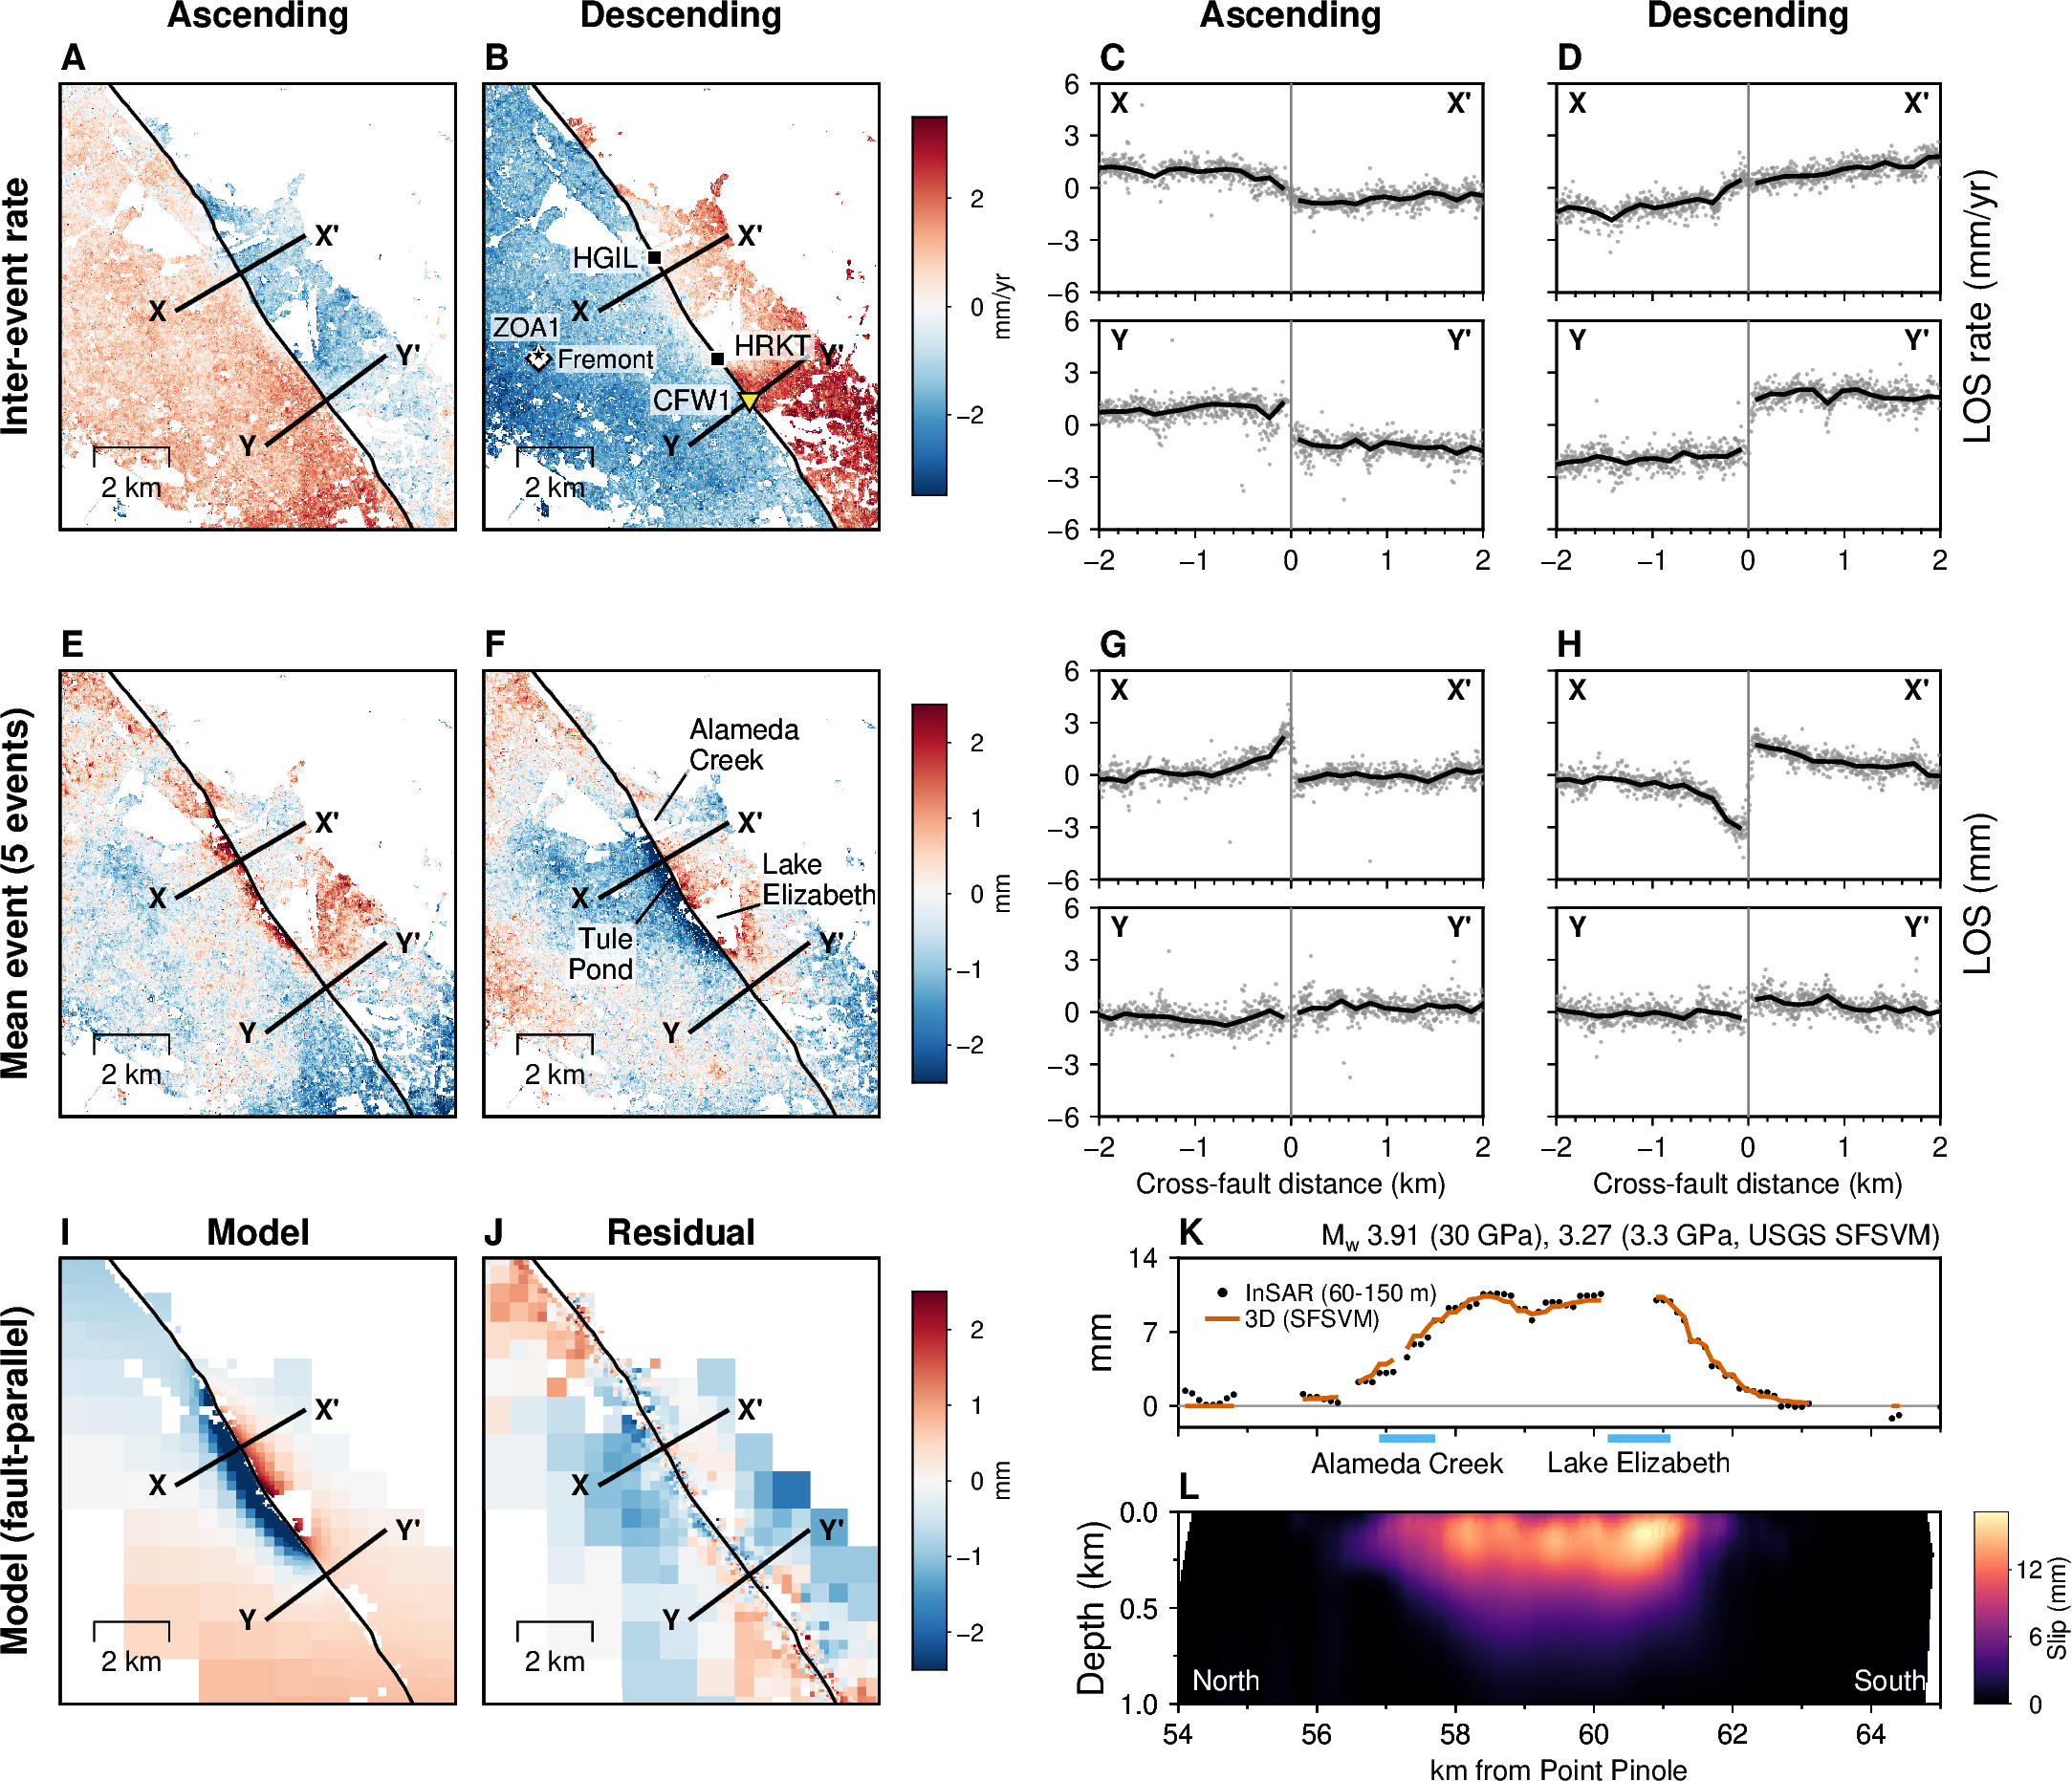

In [14]:
f_fig2_los = os.path.join(fig_dir, f"figS_los_maps_profiles_coh{coh_maps:g}_{n_mean}ev{model_tag}")
draw_fig2(masked(rate_los, mask_los), masked(event_los, mask_los), los_profiles, f"Mean event ({n_mean} events)",
          f_fig2_los, tracks, ("LOS rate (mm/yr)", "LOS (mm)"), lim_prof_los)

## 14. Fig 2: the fault-parallel and vertical fields, and the model row

Fig 2 has the layout of the LOS figure of section 13, with the two tracks replaced by the fault-parallel field
(positive right-lateral, the east block moving south-east) and the vertical field (positive up) of notebook 06. The
profiles and block amplitudes are those of notebook 06, as in its registry (`06_XX_*`, `06_YY_*`). Panel G has the two
model lines of section 9.

[fault-parallel] X-X': per block W -6.83 +/- 0.35, E +2.58 +/- 0.23 mm
[fault-parallel] Y-Y': per block W -0.37 +/- 0.35, E +1.33 +/- 0.30 mm
[vertical] X-X': per block W +0.65 +/- 0.13, E +0.35 +/- 0.10 mm
[vertical] Y-Y': per block W -0.32 +/- 0.10, E -0.04 +/- 0.13 mm


K landmarks (km from Point Pinole): Alameda Creek 56.9-57.7; Lake Elizabeth 60.2-61.1


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


Saved to: /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-01/fig2_fp_up_coh0.9_5ev_model3d_dip70w.png


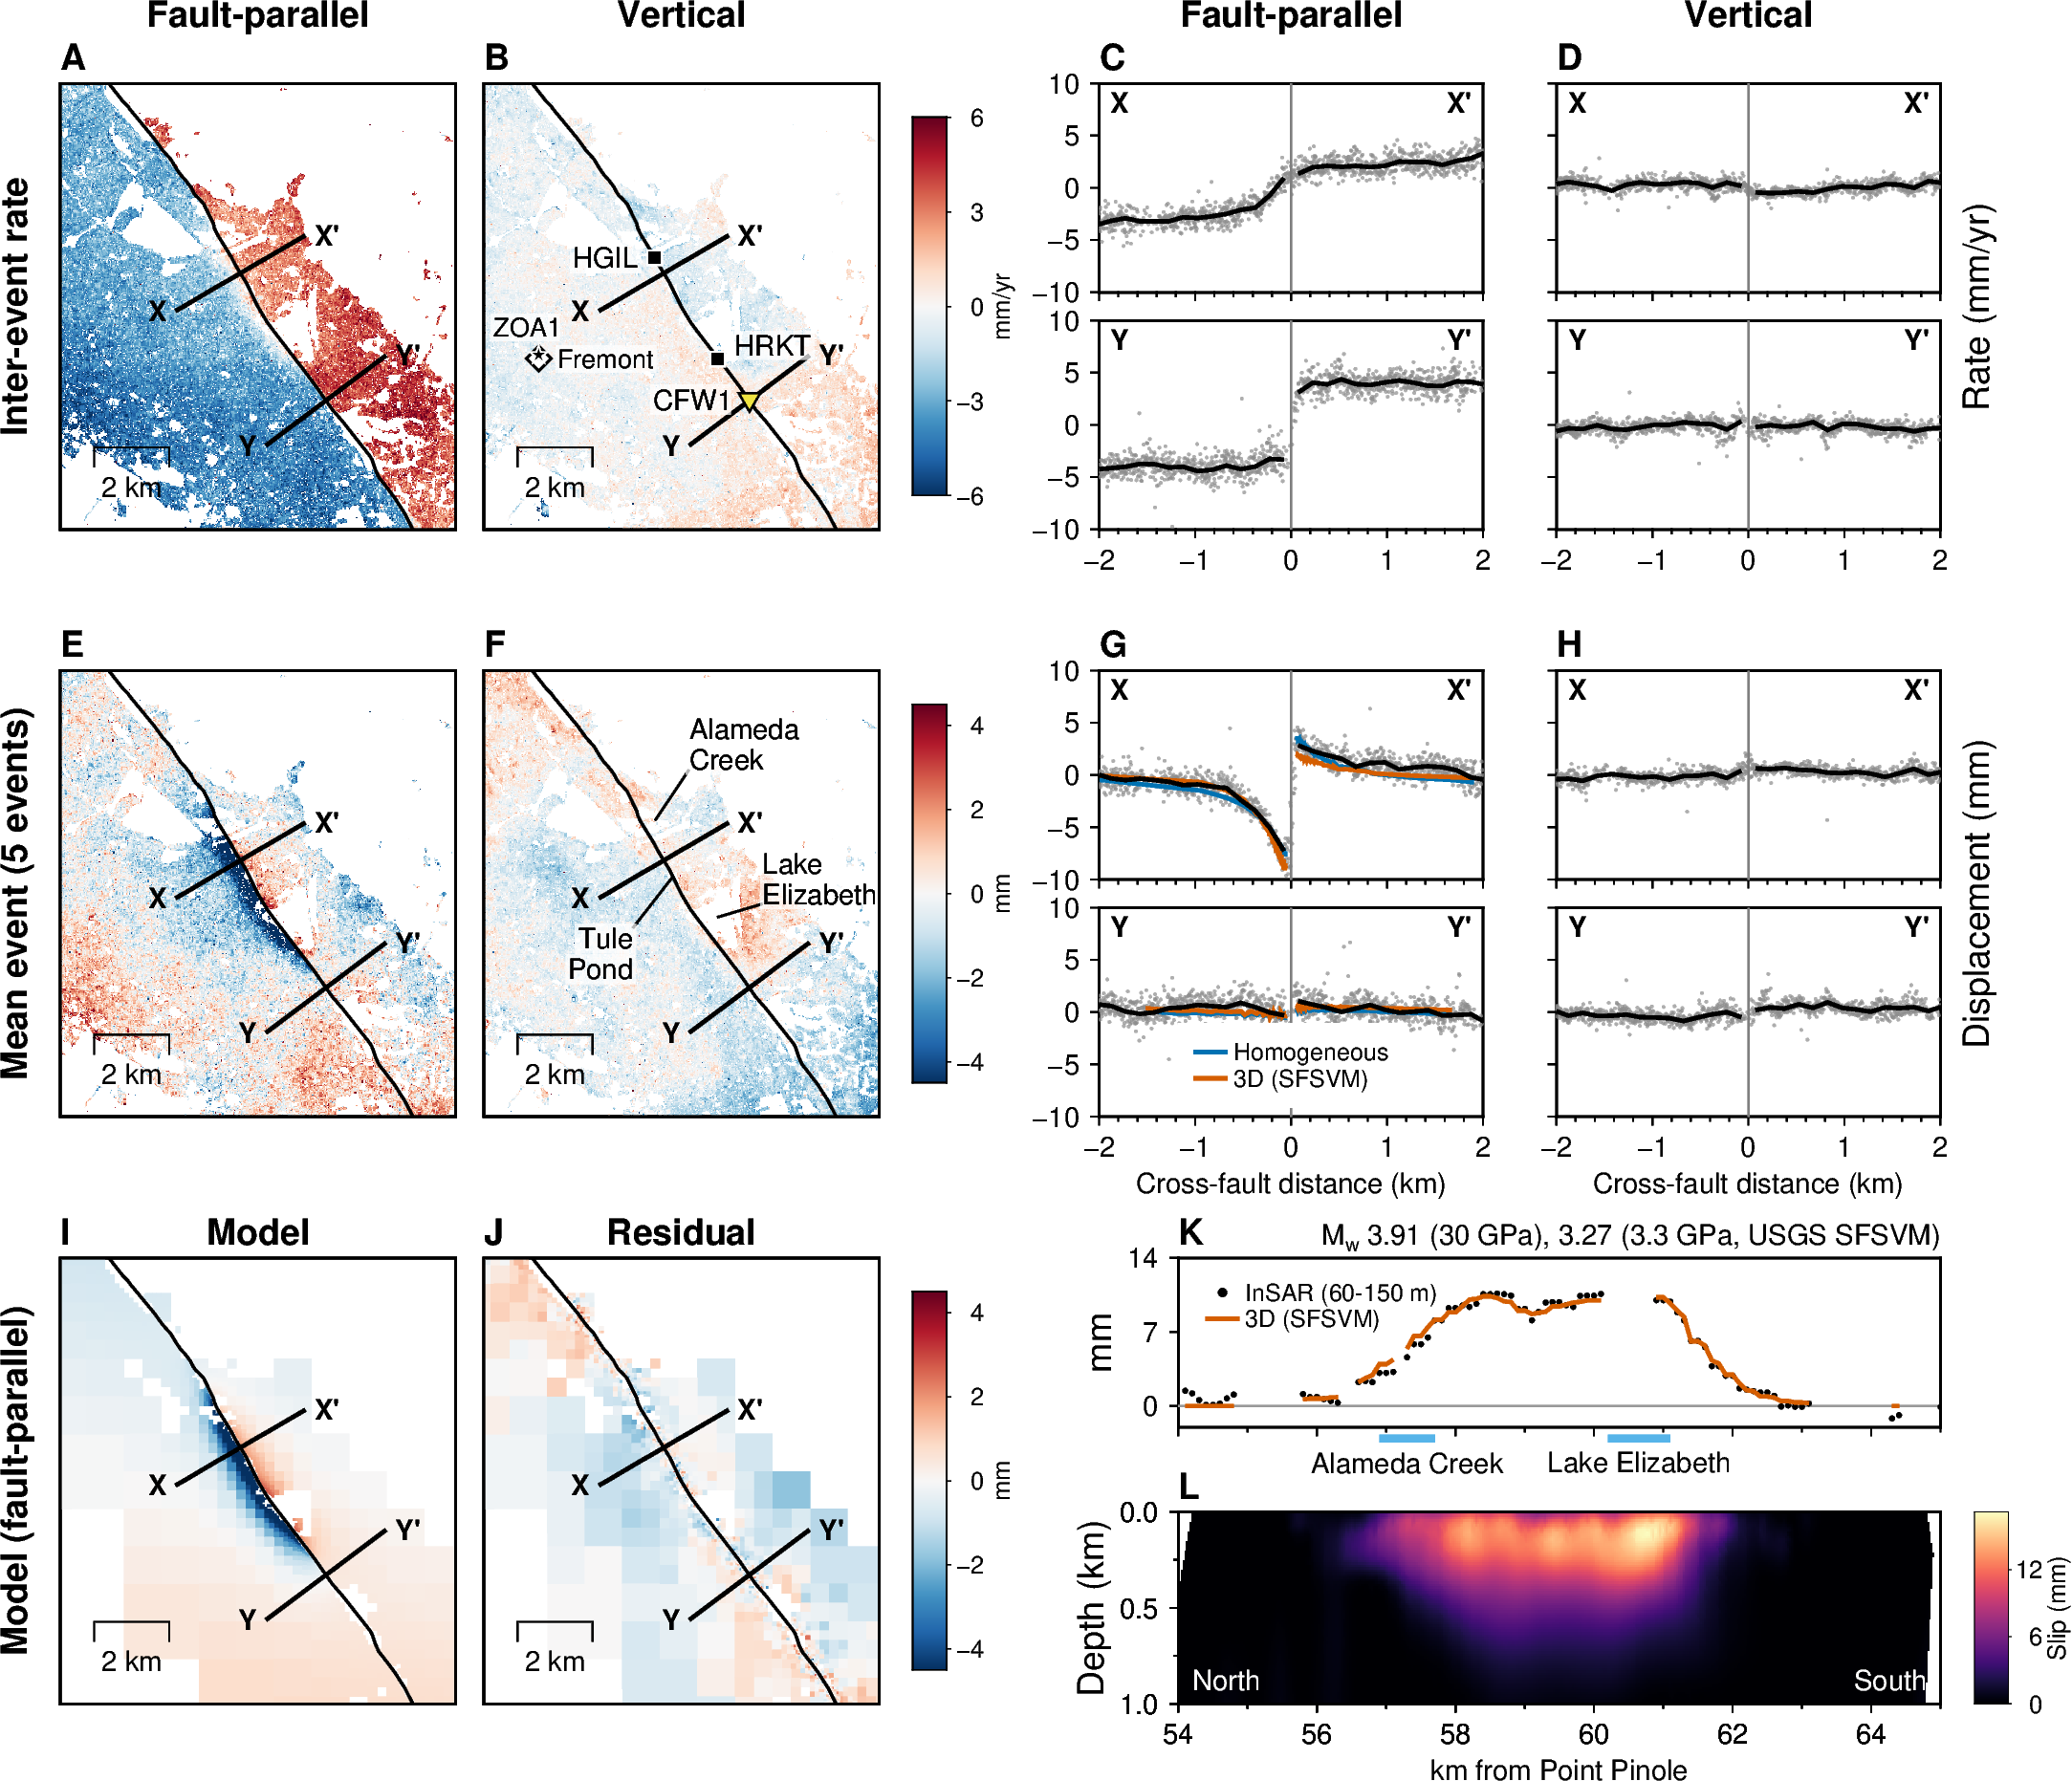

In [15]:
fpup_rate = {"fault-parallel": fig2_in["fp_rate"], "vertical": fig2_in["up_rate"]}
fpup_event = {"fault-parallel": fig2_in["fp_event"], "vertical": fig2_in["up_event"]}
fpup_profiles = {"fault-parallel": fp_profiles, "vertical": up_profiles}
for col in fpup_profiles:
    for line, profile in fpup_profiles[col].items():
        west = profile["blocks"]["W"]
        east = profile["blocks"]["E"]
        print(f"[{col}] {line}-{line}': per block W {west['amp']:+.2f} +/- {west['se']:.2f}, "
              f"E {east['amp']:+.2f} +/- {east['se']:.2f} mm")
f_fig2_fp = os.path.join(fig_dir, f"fig2_fp_up_coh{coh_maps:g}_{n_mean}ev{model_tag}")     # fp = fault-parallel, up = vertical component
draw_fig2(fpup_rate, fpup_event, fpup_profiles, f"Mean event ({n_mean} events)", f_fig2_fp,
          list(fpup_rate), ("Rate (mm/yr)", "Displacement (mm)"), lim_prof_fpup)

## 15. Fig 3: the HRKT history, the onsets on the water year, the repeat intervals and the forecast

The left column shares one time axis. A) The HRKT record with the bimonthly-era detections shaded, the years of
annual surveys greyed, the InSAR stack tied to it, the InSAR onsets dashed, and HRKT since 2015 as an inset that ends
at the data end. B) The onset windows on the water year over the 7-day rainfall. The right column shows C) the
repeat intervals of the three records quoted in the text (the array and combined records leave out the interval
spanning Loma Prieta) and D) the conditional probability of the next onset from the BPT with the fitted $\alpha$,
one line per record, with the wet season of the forecast shaded (the Working Group branches are not drawn). In C
each interval is a bar over its possible range, from $t_{\mathrm{lo},j+1} - t_{\mathrm{hi},j}$ to
$t_{\mathrm{hi},j+1} - t_{\mathrm{lo},j}$, where $t_{\mathrm{lo},j}$ and $t_{\mathrm{hi},j}$ are the ends of window
$j$. The mean and SD of each record (notebook 13, section 6; `13_<rec>_interval_mean_yr`,
`13_<rec>_interval_sd_yr`) are marked and written.

**Inputs**: 13 `fig3_inputs.npz` (the records drawn in C and D, their interval ranges, interval statistics and BPT
forecasts, the forecast grid, the last observation, the wet season of the forecast, the data end and the settings
in the file name; notebook 13, section 9); 12 `fig3_rain_panel.npz` (the rainfall grid of B and the time axis) and
`fig3_onset_windows.csv` (the onset windows); 11 `aa_insar_stacks.csv` (the InSAR stack at HRKT); the HRKT array
file. The onset windows of 12 must be the onsets of the catalogues of 13 (asserted).

**Figure**: `fig3_history_forecast_ntiming<n>_nboot<n>_issue<date>` (.png and .pdf).

In [16]:
fig_dir = common_paths["fig_dir"]
os.makedirs(fig_dir, exist_ok=True)
fig3_inputs_file = os.path.join(paths_out["13_forecast"], "fig3_inputs.npz")
rain_panel_file = os.path.join(paths_out["12_rain_seasonality"], "fig3_rain_panel.npz")
windows_file = os.path.join(paths_out["12_rain_seasonality"], "fig3_onset_windows.csv")
aa_stacks_file = os.path.join(paths_out["11_alignment_arrays"], "aa_insar_stacks.csv")

# colours (Okabe-Ito, no green) and labels
insar_colour = "#D55E00"               # Okabe-Ito vermillion: InSAR
array_colour = "#0072B2"               # Okabe-Ito blue: the alignment array
combined_colour = "#CC79A7"            # Okabe-Ito reddish purple: the combined record
onset_line_colour = "#E69F00"          # Okabe-Ito orange: InSAR onset lines
wet_shade_colour = "#56B4E9"           # Okabe-Ito sky blue: the wet season
colours = {"A_insar": insar_colour, "B_aa_dense_noLP": array_colour, "C_merged": combined_colour}
labels = {"A_insar": "InSAR", "B_aa_dense_noLP": "A. Array", "C_merged": "Combined"}
label_pt = 7

# the inputs from 13 (section 9 of 13)
fig3_in = np.load(fig3_inputs_file)
print("Fig 3 inputs:", str(fig3_in["provenance"]))
assert str(fig3_in["forecast_issue_date"]) == forecast_issue_date, \
    f"{fig3_inputs_file} was written for the issue date {fig3_in['forecast_issue_date']}, TulePond_filepaths has {forecast_issue_date}: rerun 13"
shown = fig3_in["records"].tolist()    # the array without the Loma Prieta interval; B (with it) stays in the table of 13
n_timing = int(fig3_in["n_timing"])
n_boot = int(fig3_in["n_boot"])
grid = fig3_in["grid"]
last_obs_day_yr = float(fig3_in["last_obs_day_yr"])
data_end_yr = float(fig3_in["data_end_yr"])
wet_years = fig3_in["wet_season_yr"]
interval_stats = {}                    # record -> the interval statistics of 13, section 6, drawn in C
interval_shortest = {}                 # record -> the lower end of each interval range (yr)
interval_longest = {}                  # record -> the upper end of each interval range (yr)
forecast_curves = {}                   # (record, "bpt") -> the fitted-alpha BPT forecast on the grid, drawn in D
for k, cat_name in enumerate(shown):
    interval_stats[cat_name] = dict(mean_yr=float(fig3_in["interval_mean_yr"][k]), sd_yr=float(fig3_in["interval_sd_yr"][k]),
                                    n_intervals=int(fig3_in["n_intervals"][k]))
    interval_shortest[cat_name] = fig3_in[f"interval_shortest_{cat_name}"]
    interval_longest[cat_name] = fig3_in[f"interval_longest_{cat_name}"]
    forecast_curves[(cat_name, "bpt")] = fig3_in["bpt_cdf"][k]

# the inputs of the left column, saved by 11 and 12
rain_panel = np.load(rain_panel_file)
windows = pd.read_csv(windows_file)
aa_stacks = pd.read_csv(aa_stacks_file)
hrkt = utils.load_aa(common_paths["aa_dir"], "HRKT")
hrkt_stack = aa_stacks[aa_stacks.code == "HRKT"]
x0 = float(rain_panel["x0"])
x1 = float(rain_panel["x1"])
dense_era_end = float(rain_panel["dense_era_end"])
# the catalogues drawn on the left are the ones the forecast of 13 fits: same onsets, in the same order
assert np.allclose(np.sort(windows.query("src == 'insar'").onset_lo), np.sort(fig3_in["insar_onset_lo"]), rtol=0, atol=1e-6)
assert np.allclose(np.sort(windows.query("src == 'aa_dense'").onset_lo), np.sort(fig3_in["aa_dense_onset_lo"]), rtol=0, atol=1e-6)


def onset_bar(ax, x, day_lo, day_hi, color, lw):
    """Draw a vertical bar from day_lo to day_hi of the water year at x, wrapping across 1 October if needed.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
    x : float
        Position on the time axis (decimal year).
    day_lo, day_hi : float
        Days of the water year.
    color : str
    lw : float
        Line width.
    """
    if day_hi >= day_lo:
        segments = [(day_lo, day_hi)]
    else:
        segments = [(day_lo, 366), (1, day_hi)]
    for segment_lo, segment_hi in segments:
        ax.plot([x, x], [segment_lo, segment_hi], "-", color=color, lw=lw, solid_capstyle="butt", zorder=5)
    for y in (day_lo, day_hi):
        ax.plot([x - 0.28, x + 0.28], [y, y], "-", color=color, lw=lw * 0.8, zorder=5)


# full Science width (7.2 in = 18.3 cm); panels placed by hand (inches) so the columns align whatever the labels
fig_w = 7.2
fig_h = 5.05


def place(x, y, w, h):
    """Add an axes to the figure at a position given in inches.

    Parameters
    ----------
    x, y : float
        Lower-left corner (in).
    w, h : float
        Width and height (in).

    Returns
    -------
    matplotlib.axes.Axes
    """
    return fig.add_axes([x / fig_w, y / fig_h, w / fig_w, h / fig_h])

Fig 3 inputs: 13_forecast | git 63c6907+ | 2026-11-01 13:54


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved Fig 3 to: /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-01/fig3_history_forecast_ntiming4000_nboot5_issue2026-08-25.png
Fig 3C InSAR: 4 intervals, mean 1.971 yr, SD 0.078 yr (the interval statistics of 13, section 6)
Fig 3C A. Array: 7 intervals, mean 2.547 yr, SD 0.980 yr (the interval statistics of 13, section 6)
Fig 3C Combined: 11 intervals, mean 2.338 yr, SD 0.813 yr (the interval statistics of 13, section 6)


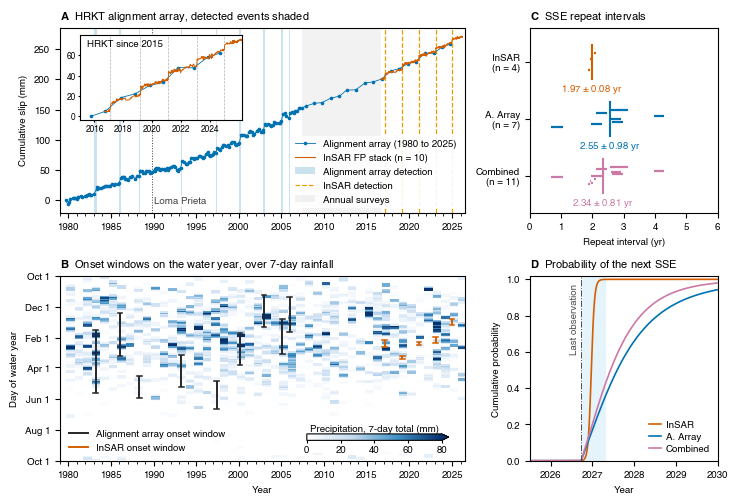

In [17]:
utils.mpl_paper_style(base=8)          # Helvetica, 8 pt, editable PDF text
fig = plt.figure(figsize=(fig_w, fig_h))
# all four panels the same height; the row gap leaves room for the x label of C above the title of D
left_x = 0.50
left_w = 4.05
right_x = 5.20
right_w = 1.88
panel_h = 1.85
row_y = (2.90, 0.42)
ax_a = place(left_x, row_y[0], left_w, panel_h)
ax_b = place(left_x, row_y[1], left_w, panel_h)
ax_c = place(right_x, row_y[0], right_w, panel_h)
ax_d = place(right_x, row_y[1], right_w, panel_h)
for ax in (ax_a, ax_b, ax_c, ax_d):
    ax.tick_params(labelsize=label_pt)

# A) the HRKT record
ax = ax_a
ax.plot(hrkt.year, hrkt.cum_mm, "o", ms=1.6, color=array_colour, lw=0.6, ls="-", zorder=3,
        label=f"Alignment array ({hrkt.year.min():.0f} to {hrkt.year.max():.0f})")
ax.plot(hrkt_stack.date, hrkt_stack.slip_mm, "-", lw=0.8, color=insar_colour, zorder=5,
        label=f"InSAR FP stack (n = {int(hrkt_stack.n_crossings.iloc[0])})")       # shifted onto the array datum (caption)
for i, window in enumerate(windows.query("src == 'aa_dense'").itertuples()):
    ax.axvspan(window.onset_lo, window.onset_hi, color=array_colour, alpha=0.20, lw=0, zorder=1,
               label="Alignment array detection" if i == 0 else None)
ax.axvspan(dense_era_end, float(rain_panel["insar_start"]), color="0.5", alpha=0.10, lw=0, zorder=0, label="Annual surveys")
for i, step_epoch in enumerate(windows.query("src == 'insar'").onset_lo):       # at each step epoch (the window is too narrow to see)
    ax.axvline(step_epoch, color=onset_line_colour, lw=0.9, ls="--", zorder=2, label="InSAR detection" if i == 0 else None)
ax.axvline(float(rain_panel["loma_prieta"]), color="0.25", lw=0.7, ls=":", zorder=2)
ax.text(float(rain_panel["loma_prieta"]) + 0.3, 0.04, "Loma Prieta", transform=ax.get_xaxis_transform(), fontsize=label_pt, color="0.25",
        ha="left", va="bottom", bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))     # between the array curve and the x axis
ax.set_ylabel("Cumulative slip (mm)", fontsize=label_pt)
handles, leg_labels = ax.get_legend_handles_labels()
legend_order = []                                       # the grey "Annual surveys" last
for i, leg_label in enumerate(leg_labels):
    if leg_label != "Annual surveys":
        legend_order.append(i)
legend_order.append(leg_labels.index("Annual surveys"))
ordered_handles = []
ordered_labels = []
for i in legend_order:
    ordered_handles.append(handles[i])
    ordered_labels.append(leg_labels[i])
ax.legend(ordered_handles, ordered_labels, fontsize=label_pt, loc="lower right", frameon=True,
          facecolor="white", edgecolor="none", framealpha=0.9)
ax.set_title(r"$\bf{A}$  HRKT alignment array, detected events shaded", loc="left", fontsize=8)
ax.set_xlim(x0, x1)                                  # year labels but no "Year" title (no space in the row gap)
# HRKT since 2015 as an inset, zeroed at its first survey
zoom_t0 = 2015.0
recent = hrkt[hrkt.year >= zoom_t0]
zero = float(recent.cum_mm.iloc[0])
inset = ax.inset_axes([0.05, 0.50, 0.40, 0.46])      # top left, above the array curve, which reaches this height only after 2010
inset.plot(recent.year, recent.cum_mm - zero, "o", ms=1.6, color=array_colour, lw=0.6, ls="-")
inset.plot(hrkt_stack.date, hrkt_stack.slip_mm - zero, "-", lw=0.7, color=insar_colour)
for step_epoch in windows.query("src == 'insar'").onset_lo:
    inset.axvline(step_epoch, color="0.7", lw=0.5, ls="--", zorder=0)
inset.set_xlim(zoom_t0, data_end_yr)                 # to the end of the InSAR record
inset.set_xticks([2016, 2018, 2020, 2022, 2024])
inset.tick_params(labelsize=6, length=1.5, pad=1.5)
inset.text(0.04, 0.95, "HRKT since 2015", transform=inset.transAxes, fontsize=label_pt, va="top")

# B) the onset windows on the water year over the 7-day rain
ax = ax_b
rain_cmap = LinearSegmentedColormap.from_list("rain", list(rain_panel["rain_colours"]))
density_max = float(rain_panel["density_max"])
density_days = int(rain_panel["density_days"])
mesh = ax.pcolormesh(rain_panel["x_edges"], np.arange(-0.5, 367.5), rain_panel["rain_grid"], cmap=rain_cmap, vmin=0, vmax=density_max,
                     shading="flat", rasterized=True, zorder=0)
for window in windows.itertuples():
    bar_colour = "0.15" if window.src == "aa_dense" else insar_colour
    onset_bar(ax, window.onset_mid, window.dowy_lo, window.dowy_hi, bar_colour, 1.4)
ax.set_ylim(366, 1)
ax.set_yticks([1, 62, 124, 182, 244, 305, 366])
ax.set_yticklabels(["Oct 1", "Dec 1", "Feb 1", "Apr 1", "Jun 1", "Aug 1", "Oct 1"])
ax.set_xlabel("Year", fontsize=label_pt)
ax.set_ylabel("Day of water year", fontsize=label_pt)
ax.add_patch(plt.Rectangle((0.575, 0.04), 0.415, 0.24, transform=ax.transAxes, facecolor="white", edgecolor="none", alpha=0.85, zorder=4))
cax = ax.inset_axes([0.61, 0.11, 0.35, 0.035])
cb = fig.colorbar(mesh, cax=cax, orientation="horizontal", extend="max")
cb.set_label(f"Precipitation, {density_days}-day total (mm)", fontsize=label_pt, labelpad=2)
cb.ax.xaxis.set_label_position("top")
cb.ax.tick_params(labelsize=label_pt, length=2, pad=1.5)
ax.legend(handles=[Line2D([], [], color="0.15", lw=1.4, label="Alignment array onset window"),
                   Line2D([], [], color=insar_colour, lw=1.4, label="InSAR onset window")], fontsize=label_pt, loc="lower left",
          frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
ax.set_title(r"$\bf{B}$  Onset windows on the water year, over 7-day rainfall", loc="left", fontsize=8)
ax.set_xlim(x0, x1)
for ax in (ax_a, ax_b):                              # annual ticks, years labelled every 5 (B; A shares the axis)
    ax.xaxis.set_major_locator(MultipleLocator(5))
    ax.xaxis.set_minor_locator(MultipleLocator(1))

# C) the repeat intervals of each catalogue: each interval as a bar over its possible range (from the end of the earlier
# window to the start of the later one, up to the start of the earlier to the end of the later; computed in 13), the
# mean of the onset draws marked, mean and sd written under it
ax = ax_c
tick_labels = []
fig3c_numbers = {}                 # catalogue -> (mean, sd, number of intervals): interval_stats of 13, section 6, printed
for j, cat_name in enumerate(shown):
    shortest = interval_shortest[cat_name]
    longest = interval_longest[cat_name]
    rows_y = j + np.linspace(-0.15, 0.15, len(shortest))
    ax.hlines(rows_y, shortest, longest, color=colours[cat_name], lw=1.6)
    mean_yr = interval_stats[cat_name]["mean_yr"]
    sd_yr = interval_stats[cat_name]["sd_yr"]
    assert interval_stats[cat_name]["n_intervals"] == len(shortest), f"{cat_name}: Fig 3C draws {len(shortest)} intervals, section 6 of 13 has a different count"
    fig3c_numbers[cat_name] = (mean_yr, sd_yr, len(shortest))
    ax.plot([mean_yr, mean_yr], [j - 0.3, j + 0.3], "-", color=colours[cat_name], lw=1.5)
    ax.text(mean_yr, j + 0.36, f"{mean_yr:.2f} $\\pm$ {sd_yr:.2f} yr", ha="center", va="top", fontsize=7, color=colours[cat_name])
    tick_labels.append(f"{labels[cat_name]}\n(n = {len(shortest)})")      # the record spans are shown in A
ax.set_yticks(range(len(shown)))
ax.set_yticklabels(tick_labels, fontsize=label_pt, linespacing=1.1)
ax.set_ylim(len(shown) - 0.35, -0.6)          # inverted: first catalogue on top; room under the last bar for its number
ax.set_xlim(0, 6)
ax.set_xlabel("Repeat interval (yr)", fontsize=label_pt)
ax.set_title(r"$\bf{C}$  SSE repeat intervals", loc="left", fontsize=8)

# D) the conditional forecast, BPT, one line per catalogue; the wet season shaded, the last observation marked
ax = ax_d
ax.axvspan(wet_years[0], wet_years[1], color=wet_shade_colour, alpha=0.15, lw=0)
for cat_name in shown:
    ax.plot(grid, forecast_curves[(cat_name, "bpt")], "-", color=colours[cat_name], lw=1.2, label=labels[cat_name])
ax.axvline(last_obs_day_yr, color="0.3", lw=0.7, ls="-.")
ax.text(last_obs_day_yr - 0.06, 0.98, "Last observation", fontsize=label_pt, color="0.3", va="top", ha="right", rotation=90)   # left of the line, clear of the InSAR curve
ax.set_xlim(2025.5, 2030.0)
ax.xaxis.set_major_locator(MultipleLocator(1))
ax.set_ylim(0, 1.02)
ax.set_xlabel("Year", fontsize=label_pt)
ax.set_ylabel("Cumulative probability", fontsize=label_pt)
ax.set_title(r"$\bf{D}$  Probability of the next SSE", loc="left", fontsize=8)
ax.legend(fontsize=label_pt, loc="lower right", handlelength=1.2, handletextpad=0.5, borderpad=0.3, labelspacing=0.3,
          frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
f_fig3 = os.path.join(fig_dir, f"fig3_history_forecast_ntiming{n_timing}_nboot{n_boot}_issue{forecast_issue_date}.png")
fig.savefig(f_fig3, dpi=600)
fig.savefig(f_fig3.replace(".png", ".pdf"))
print("Saved Fig 3 to:", f_fig3)
for cat_name, (mean_yr, sd_yr, n_shown) in fig3c_numbers.items():
    print(f"Fig 3C {labels[cat_name]}: {n_shown} intervals, mean {mean_yr:.3f} yr, SD {sd_yr:.3f} yr (the interval statistics of 13, section 6)")
plt.show()

## 16. Collect, check and copy the paper figures

The latest run of a notebook starts at the earliest cell start and ends at the last cell reply recorded in the
executed `<notebook>.ipynb` (written by `run_all.sh` through nbconvert); the cells must have run top to bottom.
Let $t_0(n)$ and $t_1(n)$ be the start and end of the latest run of notebook $n$, and $t_w(f)$ the time a figure
file $f$ was written. A figure $f$ drawn by notebook $n$ is stale if

$$t_w(f) < t_0(n) \quad \text{or} \quad t_1(m) > t_0(n) \ \text{for any notebook } m \text{ that } n \text{ reads},$$

that is, if the latest run of $n$ did not write it, or if $n$ last started before a notebook it reads had
finished (for example when 08 has been rerun but 09 has not, or when 09 failed: nbconvert does not save a
failed notebook, so its record is not updated). All times are in UTC. The cell stops if a figure is missing, if
a pattern matches more than one file (so that an outdated variant is never selected), or if a figure is stale.
The figures drawn in this notebook (Figs 1 to 3 and the line-of-sight version of Fig 2) must be written after the
start of this run. The dictionary `wanted` lists every figure with its file pattern and the notebook that draws it;
`reads_from` lists the notebooks whose products each of those notebooks reads.

In [18]:
fig_dir = common_paths["fig_dir"]
paper = os.path.join(fig_dir, "paper")
os.makedirs(paper, exist_ok=True)

# paper name -> (file pattern in fig_dir, notebook that draws it)
wanted = {
    "Fig_1": ("fig1_tulepond_*.png", "14_paper_figures"),
    "Fig_2": (f"fig2_fp_up_*ev{model_tag}.png", "14_paper_figures"),                       # the preferred 3D (SFSVM) model of 09
    "Fig_3": ("fig3_history_forecast_*.png", "14_paper_figures"),
    "Fig_S_velocity_chain": ("figS_velocity_chain_*.png", "01_prep_figures"),
    "Fig_S_gnss_tie": ("figS_gnss_tie_*.png", "01_prep_figures"),
    "Fig_S_ratemask": ("figS_ratemask_*.png", "03_creep_timeseries"),
    "Fig_S_acquisitions": ("figS_acquisitions_*.png", "03_creep_timeseries"),
    "Fig_S_event_detection": ("figS_event_detection_*.png", "04_event_detection"),
    "Fig_S_creep_rate_along_fault": ("figS_creep_rate_along_fault_*.png", "04_event_detection"),
    "Fig_S_los_maps_profiles": (f"figS_los_maps_profiles_*ev{model_tag}.png", "14_paper_figures"),
    "Fig_S_event_step_maps": ("figS_event_step_maps_*.png", "06_event_field_geometry"),
    "Fig_S_validation": ("figS_validation_*.png", "05_validation"),
    "Fig_S_binning_ladder": ("figS_binning_ladder_*.png", "05_validation"),
    "Fig_S_arrays_insar": ("figS_tulepond_arrays_insar_*.png", "11_alignment_arrays"),
    "Fig_S_hrkt_threshold": ("figS_hrkt_threshold_sweep_*.png", "11_alignment_arrays"),
    "Fig_S_aa_history_HRKT": ("qc_aa_history_HRKT_*.png", "11_alignment_arrays"),
    "Fig_S_aa_history_HAPP": ("qc_aa_history_HAPP_*.png", "11_alignment_arrays"),
    "Fig_S_precip_conditioning": ("figS_precip_conditioning_*.png", "12_rain_seasonality"),
    "Fig_S_renewal_single_fits": ("qc_renewal_models_single_fits.png", "13_forecast"),
    "Fig_S_model_lcurve": (f"figS_model_lcurve_{cfg.selected_dip_tag}.png", "09_model_3d"),
    "Fig_S_model_slip": (f"figS_model_slip_{cfg.selected_dip_tag}.png", "09_model_3d"),
    "Fig_S_model_fit_maps": (f"figS_model_fit_maps_{cfg.selected_dip_tag}.png", "09_model_3d"),
    "Fig_S_model_profiles": (f"figS_model_profiles_{cfg.selected_dip_tag}.png", "09_model_3d"),
    "Fig_S_model_montecarlo": (f"figS_model_montecarlo_{cfg.selected_dip_tag}.png", "09_model_3d"),
    "Fig_S_pylith_materials": ("figS_pylith_materials_sfcvm_v26.png", "09_model_3d"),       # scripts/model_plots/plot_materials.py
    "Fig_S_sweeps": (f"figS_sweeps_{cfg.selected_dip_tag}.png", "10_model_sensitivity"),
    "Fig_S_depth_scan": (f"figS_depth_scan_{cfg.selected_dip_tag}.png", "10_model_sensitivity"),
    "Fig_S_gf_error_vs_depth": ("figS_gf_error_vs_depth.png", "10_model_sensitivity"),
    "Fig_S_semivariogram": ("figS_semivariogram.png", "10_model_sensitivity"),
}
# the notebooks whose products each source notebook reads (01_prep_figures and 03 read only the prepared data)
reads_from = {
    "01_prep_figures": [],
    "03_creep_timeseries": [],
    "04_event_detection": ["02_velocity_decomposition", "03_creep_timeseries"],
    "05_validation": ["02_velocity_decomposition", "03_creep_timeseries", "04_event_detection"],
    "06_event_field_geometry": ["04_event_detection"],
    "07_model_data": ["04_event_detection", "06_event_field_geometry"],
    "09_model_3d": ["04_event_detection", "06_event_field_geometry", "07_model_data", "08_model_homogeneous"],
    "08_model_homogeneous": ["07_model_data"],
    "10_model_sensitivity": ["07_model_data", "09_model_3d"],
    "11_alignment_arrays": ["03_creep_timeseries", "04_event_detection", "06_event_field_geometry"],
    "12_rain_seasonality": ["03_creep_timeseries", "04_event_detection", "11_alignment_arrays"],
    "13_forecast": ["03_creep_timeseries", "04_event_detection", "11_alignment_arrays", "12_rain_seasonality"],
}


def latest_run(notebook):
    """Start and end of a notebook's latest recorded run.

    nbconvert records the start and the reply of every code cell in the executed .ipynb. The run starts at the
    first cell's start and ends at the last cell's reply. Stops if a record is missing or if the cells did not
    run top to bottom.

    Parameters
    ----------
    notebook : str
        Notebook name without extension, e.g. "04_event_detection".

    Returns
    -------
    start, end : pandas.Timestamp
        Start and end of the run (UTC).
    """
    path = os.path.join(repo_dir, f"{notebook}.ipynb")
    with open(path) as f:
        cells = json.load(f)["cells"]
    starts = []
    ends = []
    for cell in cells:
        if cell["cell_type"] != "code":
            continue
        timing = cell.get("metadata", {}).get("execution", {})
        assert "iopub.execute_input" in timing and "shell.execute_reply" in timing, \
            f"{path}: a code cell has no execution record; run the notebook with run_all.sh"
        starts.append(pd.Timestamp(timing["iopub.execute_input"]))
        ends.append(pd.Timestamp(timing["shell.execute_reply"]))
    assert starts, f"{path} has no code cells"
    assert all(a <= b for a, b in zip(starts, starts[1:])), f"{path}: the cells did not run top to bottom; rerun it with run_all.sh"
    return starts[0], ends[-1]


def mtime_utc(path):
    """Modification time of a file.

    Parameters
    ----------
    path : str
        File path.

    Returns
    -------
    pandas.Timestamp
        Modification time (UTC).
    """
    return pd.Timestamp(os.path.getmtime(path), unit="s", tz="UTC")


runs = {}
for notebook in (set(source for _, source in wanted.values()) | {n for upstream in reads_from.values() for n in upstream}) - {"14_paper_figures"}:
    runs[notebook] = latest_run(notebook)

missing = []
stale = []
for name, (pattern, source_notebook) in wanted.items():
    hits = glob.glob(os.path.join(fig_dir, pattern))
    if len(hits) == 0:
        missing.append(f"{name} ({pattern})")
        continue
    assert len(hits) == 1, f"{name}: {len(hits)} files match {pattern}: {hits}"
    source = hits[0]
    if source_notebook == "14_paper_figures":                 # drawn above in this run
        written = mtime_utc(source)
        if written < this_run_start:
            stale.append(f"{name}: {os.path.basename(source)} was not written by this run of 14_paper_figures")
        print(f"{name:26s} <- {os.path.basename(source)}  (drawn above)")
        continue
    run_start, run_end = runs[source_notebook]
    # check that the source notebook ran after every notebook it reads, and that the figure was written by that run
    for upstream in reads_from[source_notebook]:
        if runs[upstream][1] > run_start:
            stale.append(f"{name}: {source_notebook} last ran {run_start:%Y-%m-%d %H:%M}Z, before {upstream} finished "
                         f"{runs[upstream][1]:%Y-%m-%d %H:%M}Z; rerun {source_notebook}")
    note = ""
    for extension in (".png", ".pdf"):
        source_file = source.replace(".png", extension)
        if not os.path.exists(source_file):
            continue
        written = mtime_utc(source_file)
        if written < run_start:
            stale.append(f"{name}: {os.path.basename(source_file)} written {written:%Y-%m-%d %H:%M}Z, before {source_notebook}'s "
                         f"latest run started {run_start:%Y-%m-%d %H:%M}Z (that run did not write it)")
        elif written > run_end:
            note = f"  [written after the recorded run of {source_notebook}: a run outside nbconvert]"
    print(f"{name:26s} <- {os.path.basename(source)}  ({source_notebook}, run {run_start:%Y-%m-%d %H:%M}Z){note}")
assert not missing, f"paper figures missing in {fig_dir}: {missing}"
assert not stale, "Stale paper figures, not collected:\n  " + "\n  ".join(stale)
for name, (pattern, source_notebook) in wanted.items():
    source = glob.glob(os.path.join(fig_dir, pattern))[0]
    for extension in (".png", ".pdf"):
        source_file = source.replace(".png", extension)
        if os.path.exists(source_file):
            shutil.copy(source_file, os.path.join(paper, name + extension))
print("collected in", paper)

Fig_1                      <- fig1_tulepond_ap30-150m_coh0.7_mp5_sw200m_band90.png  (drawn above)
Fig_2                      <- fig2_fp_up_coh0.9_5ev_model3d_dip70w.png  (drawn above)
Fig_3                      <- fig3_history_forecast_ntiming4000_nboot5_issue2026-08-25.png  (drawn above)
Fig_S_velocity_chain       <- figS_velocity_chain_coh0.7_vel9_ramp1.png  (01_prep_figures, run 2026-11-01 00:55Z)
Fig_S_gnss_tie             <- figS_gnss_tie_coh0.7_nasc30_ndesc29.png  (01_prep_figures, run 2026-11-01 00:55Z)
Fig_S_ratemask             <- figS_ratemask_ap30-150m_coh0.7_mp5_sw200m_nsigma3.png  (03_creep_timeseries, run 2026-10-31 23:35Z)
Fig_S_acquisitions         <- figS_acquisitions_ap30-150m_coh0.7_mp5_sw200m_gap45d.png  (03_creep_timeseries, run 2026-10-31 23:35Z)
Fig_S_event_detection      <- figS_event_detection_ap30-150m_coh0.7_mp5_sw200m_k3_win3.png  (04_event_detection, run 2026-10-31 23:36Z)
Fig_S_creep_rate_along_fault <- figS_creep_rate_along_fault_ap30-150m_coh0.7_mp5_sw20

collected in /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-01/paper
